# Описание кейса из kaggle 

Данный набор данных был любезно предоставлен компанией Olist — крупнейшим оператором, объединяющим продавцов на различных торговых площадках Бразилии. Olist помогает представителям малого бизнеса со всей страны выходить на каналы продаж без лишних сложностей, предлагая единый договор. Продавцы могут реализовывать свои товары через платформу Olist и отправлять их покупателям напрямую, используя логистических партнеров компании. Подробнее — на нашем сайте: www.olist.com

После того как клиент совершает покупку через Olist, продавец получает уведомление о необходимости выполнить заказ. Когда товар доставлен (или наступает ожидаемая дата доставки), покупателю по электронной почте приходит опрос, в котором он может оценить свой опыт покупки и оставить комментарий.

Важное примечание
Один заказ может включать несколько товаров.
Каждый товар может быть предоставлен отдельным продавцом.
Все названия магазинов и партнеров в тексте были заменены на названия великих домов из «Игры престолов».

# Первичный просмотр и предобработка данных Olist
Кейс 1: «Исследование факторов, влияющих на своевременную доставку и удовлетворённость клиентов».

На этом этапе мы загружаем таблицы, смотрим, что в них есть, ищем пропуски, дубликаты и странные значения, и разбираемся, как таблицы связаны между собой. Глубокий анализ — на следующих этапах.

Данные: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). CSV-файлы нужно положить в папку `data/`. Таблица геолокации большая, поэтому хранится в архиве `olist_geolocation_dataset.zip` — pandas читает его без распаковки.

In [1]:
import pandas as pd

DATA_DIR = 'data/'
files = {
    'orders':    'olist_orders_dataset.csv',
    'items':     'olist_order_items_dataset.csv',
    'reviews':   'olist_order_reviews_dataset.csv',
    'payments':  'olist_order_payments_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'products':  'olist_products_dataset.csv',
    'sellers':   'olist_sellers_dataset.csv',
    'cat_tr':    'product_category_name_translation.csv',
}
df = {name: pd.read_csv(DATA_DIR + f) for name, f in files.items()}

In [2]:
df['geo'] = pd.read_csv(DATA_DIR + 'olist_geolocation_dataset.csv')

## 1. Размер таблиц и столбцы

In [3]:
for name, t in df.items():
    print(f'{name}: {t.shape[0]} строк, {t.shape[1]} столбцов')
    print('   ', list(t.columns))

orders: 99441 строк, 8 столбцов
    ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
items: 112650 строк, 7 столбцов
    ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
reviews: 99224 строк, 7 столбцов
    ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
payments: 103886 строк, 5 столбцов
    ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
customers: 99441 строк, 5 столбцов
    ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
products: 32951 строк, 9 столбцов
    ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'produc

## 2. Пропуски

In [4]:
for name, t in df.items():
    na = t.isna().sum()
    na = na[na > 0]
    if len(na):
        print(f'--- {name}')
        print(na.to_string())

--- orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
--- reviews
review_comment_title      87656
review_comment_message    58247
--- products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


## 3. Дубликаты

In [5]:
for name, t in df.items():
    print(f'{name}: полных дубликатов строк — {t.duplicated().sum()}')
print()
print('Заказов с несколькими товарами:', (df['items'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими оплатами:', (df['payments'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими отзывами:', (df['reviews'].groupby('order_id').size() > 1).sum())

orders: полных дубликатов строк — 0
items: полных дубликатов строк — 0
reviews: полных дубликатов строк — 0
payments: полных дубликатов строк — 0
customers: полных дубликатов строк — 0
products: полных дубликатов строк — 0
sellers: полных дубликатов строк — 0
cat_tr: полных дубликатов строк — 0
geo: полных дубликатов строк — 261831

Заказов с несколькими товарами: 9803
Заказов с несколькими оплатами: 2961
Заказов с несколькими отзывами: 547


## 4. Статусы заказов и даты
Даты хранятся как текст — переводим в формат даты.

In [6]:
orders = df['orders'].copy()
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders['order_status'].value_counts().to_string())
print()
print('Период покупок:', orders['order_purchase_timestamp'].min().date(), '—', orders['order_purchase_timestamp'].max().date())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Период покупок: 2016-09-04 — 2018-10-17


In [7]:
orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

## 5. Странные значения в датах

In [8]:
dl = orders[orders['order_status'] == 'delivered']
print('Доставленных заказов:', len(dl))
print('Доставлены, но нет даты доставки:', dl['order_delivered_customer_date'].isna().sum())
print('Передача перевозчику раньше покупки:', (dl['order_delivered_carrier_date'] < dl['order_purchase_timestamp']).sum())
print('Доставка покупателю раньше передачи перевозчику:', (dl['order_delivered_customer_date'] < dl['order_delivered_carrier_date']).sum())

Доставленных заказов: 96478
Доставлены, но нет даты доставки: 8
Передача перевозчику раньше покупки: 165
Доставка покупателю раньше передачи перевозчику: 23


## 6. Как связаны таблицы
Главная таблица — заказы (`order_id`). К ней по `order_id` присоединяются товары, оплаты и отзывы, по `customer_id` — покупатели. Товары связаны с карточками товаров (`product_id`) и продавцами (`seller_id`). Геолокация связана с покупателями и продавцами только через префикс почтового индекса (`zip_code_prefix`).

In [9]:
o_ids = set(orders['order_id'])
print('order_id уникален в заказах:', orders['order_id'].is_unique)
print('Товары без заказа:', (~df['items']['order_id'].isin(o_ids)).sum())
print('Отзывы без заказа:', (~df['reviews']['order_id'].isin(o_ids)).sum())
print('Заказы без покупателя:', (~orders['customer_id'].isin(df['customers']['customer_id'])).sum())
print('Товары без продавца:', (~df['items']['seller_id'].isin(df['sellers']['seller_id'])).sum())

order_id уникален в заказах: True
Товары без заказа: 0
Отзывы без заказа: 0
Заказы без покупателя: 0
Товары без продавца: 0


## 7. Таблица геолокации
В таблице координаты (широта и долгота) для префиксов почтовых индексов. Она может пригодиться, чтобы посчитать расстояние между продавцом и покупателем.

In [10]:
geo = df['geo']
print('Строк:', len(geo), '| уникальных индексов:', geo['geolocation_zip_code_prefix'].nunique())
print('Полных дубликатов:', geo.duplicated().sum())
in_brazil = geo['geolocation_lat'].between(-33.8, 5.3) & geo['geolocation_lng'].between(-74, -34.7)
print('Координаты за пределами Бразилии:', (~in_brazil).sum())
zips = set(geo['geolocation_zip_code_prefix'])
print('Покупатели, чьего индекса нет в геолокации:', (~df['customers']['customer_zip_code_prefix'].isin(zips)).sum())
print('Продавцы, чьего индекса нет в геолокации:', (~df['sellers']['seller_zip_code_prefix'].isin(zips)).sum())
print('Примеры написания Сан-Паулу:', list(geo.loc[geo['geolocation_city'].str.contains('paulo') & (geo['geolocation_state'] == 'SP'), 'geolocation_city'].unique()[:4]))

Строк: 1000163 | уникальных индексов: 19015
Полных дубликатов: 261831
Координаты за пределами Бразилии: 42
Покупатели, чьего индекса нет в геолокации: 278
Продавцы, чьего индекса нет в геолокации: 7
Примеры написания Сан-Паулу: ['sao paulo', 'são paulo', 'sãopaulo', 'sa£o paulo']


## Что мы поняли
- Таблицы связываются между собой без потерь.
- В одном заказе может быть несколько товаров, оплат и отзывов — перед объединением их нужно свести к одной строке на заказ, иначе суммы задвоятся.
- Даты нужно переводить из текста в формат даты.
- Для анализа доставки подходят заказы со статусом `delivered` и известной датой доставки.
- В начале (2016) и в конце (сентябрь–октябрь 2018) периода заказов очень мало — эти месяцы, скорее всего, уберём.
- Есть небольшое число заказов со странными датами — нужно решить, удалять ли их.
- У части товаров нет категории.
- В геолокации много дубликатов, есть ошибочные координаты за пределами Бразилии и разное написание городов. На один индекс приходится много точек — если будем считать расстояния, нужно свести их к одной точке на индекс (например, среднее).

**Следующий шаг:** объединить таблицы и создать признаки (опоздание, срок доставки, доставка в другой штат и т. д.). Решить в команде, используем ли расстояние до покупателя.

# Объединение таблиц

In [11]:
df_orders = df['orders']
df_order_items = df['items']
df_order_reviews = df['reviews']
df_order_payments = df['payments']
df_sellers = df['sellers']
df_customers = df['customers']
df_products  = df['products']
df_category_name = df['cat_tr']
df_geo = df['geo']

В этом наборе данных содержится информация о клиенте и его местоположении. 

В нашей системе каждому заказу присваивается уникальный `customer_id`. 
Это означает, что один и тот же клиент может иметь разные идентификаторы для разных заказов. Наличие в наборе данных поля `customer_unique_id` позволяет выявлять клиентов, совершавших повторные покупки в магазине. В противном случае каждый заказ выглядел бы так, будто он сделан отдельным, уникальным клиентом.

Пожалуйста, ознакомьтесь со схемой данных:

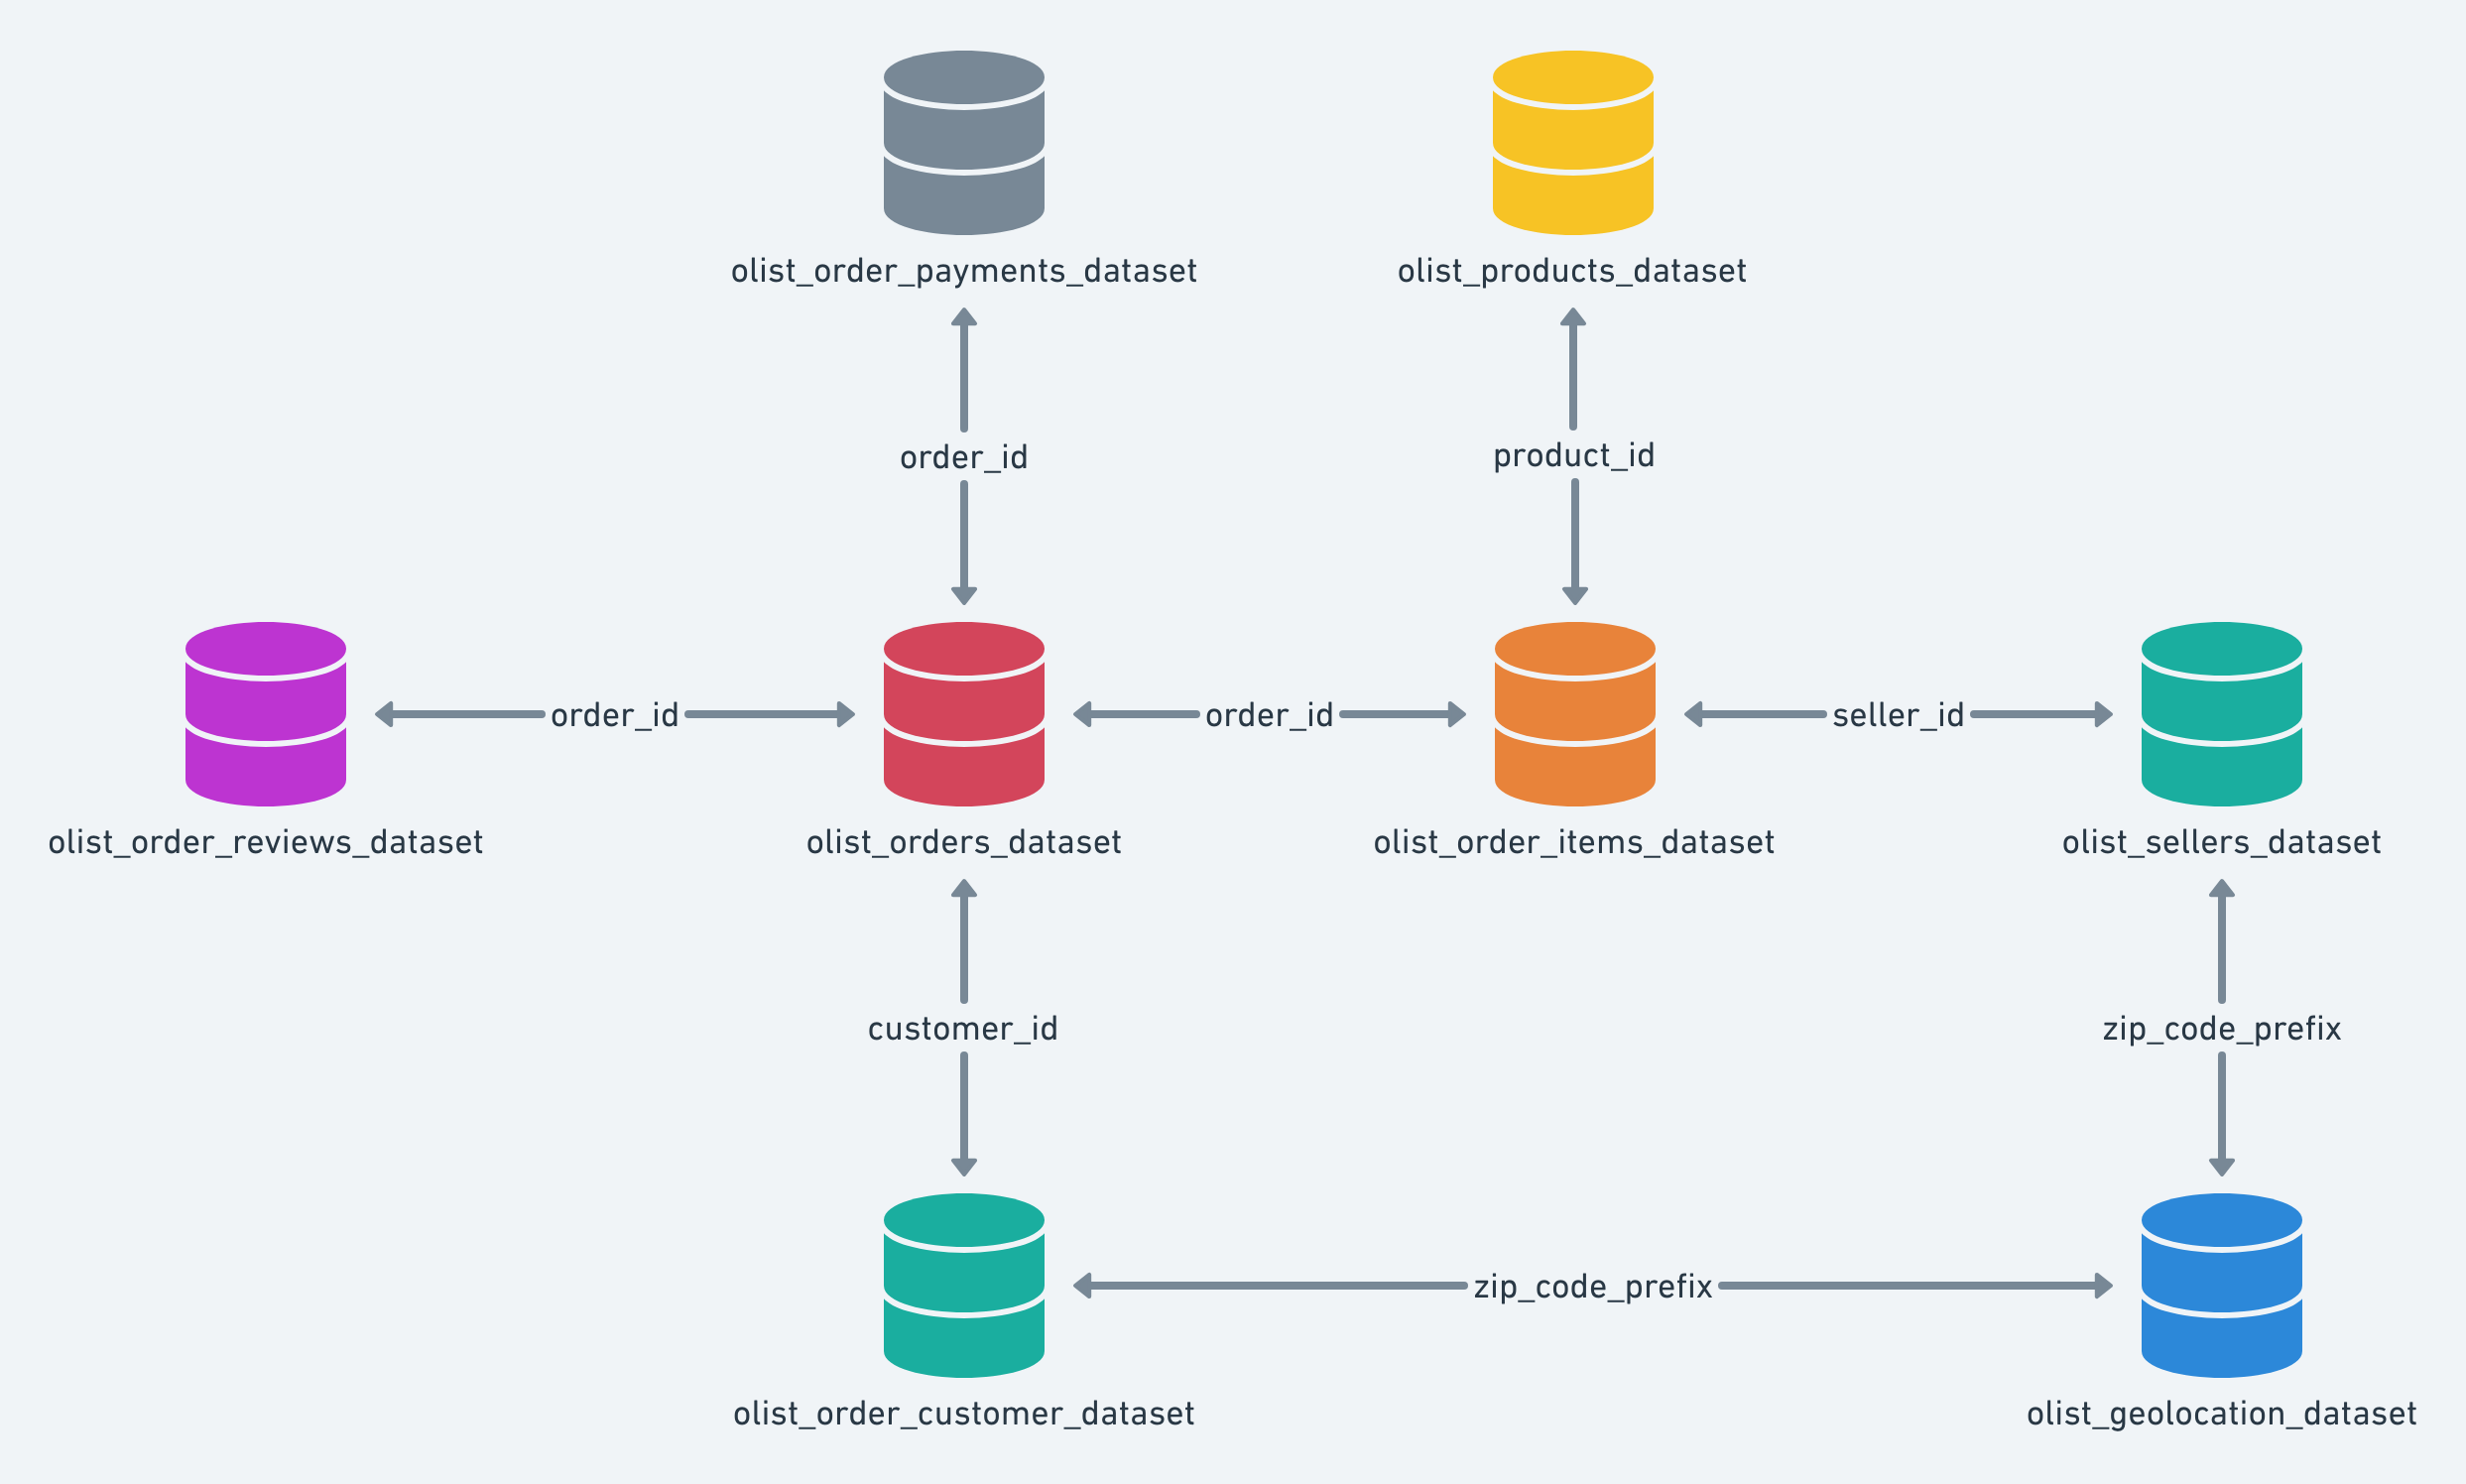

### Соединение заказов и продуктов

In [12]:
df_orders.info()
df_orders.describe()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [13]:
df_order_items.info()
df_order_items.describe()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [14]:
df_orders_full = df_orders.merge(df_order_items, how='left', on='order_id')
df_orders_full.info()
df_orders_full.describe()

<class 'pandas.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 14 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  str    
 1   customer_id                    113425 non-null  str    
 2   order_status                   113425 non-null  str    
 3   order_purchase_timestamp       113425 non-null  str    
 4   order_approved_at              113264 non-null  str    
 5   order_delivered_carrier_date   111457 non-null  str    
 6   order_delivered_customer_date  110196 non-null  str    
 7   order_estimated_delivery_date  113425 non-null  str    
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  str    
 10  seller_id                      112650 non-null  str    
 11  shipping_limit_date            112650 non-null  str    
 12  price                          112650 non

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [15]:
df_orders_products = df_orders_full.merge(df_products, how='left', on='product_id')
df_orders_products.info()
df_orders_products.describe()

<class 'pandas.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  str    
 1   customer_id                    113425 non-null  str    
 2   order_status                   113425 non-null  str    
 3   order_purchase_timestamp       113425 non-null  str    
 4   order_approved_at              113264 non-null  str    
 5   order_delivered_carrier_date   111457 non-null  str    
 6   order_delivered_customer_date  110196 non-null  str    
 7   order_estimated_delivery_date  113425 non-null  str    
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  str    
 10  seller_id                      112650 non-null  str    
 11  shipping_limit_date            112650 non-null  str    
 12  price                          112650 non

,order_item_id,price,freight_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112650.000000,112650.000000,112650.000000,111047.000000,111047.000000,111047.000000,112632.000000,112632.000000,112632.000000,112632.000000
mean,1.197834,120.653739,19.990320,48.775978,787.867029,2.209713,2093.672047,30.153669,16.593766,22.996546
std,0.705124,183.633928,15.806405,10.025581,652.135608,1.721438,3751.596884,16.153449,13.443483,11.707268
min,1.000000,0.850000,0.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,39.900000,13.080000,42.000000,348.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,74.990000,16.260000,52.000000,603.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,1.000000,134.900000,21.150000,57.000000,987.000000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,21.000000,6735.000000,409.680000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [16]:
df_orders_products.tail(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,1.0,f1d4ce8c6dd66c47bbaa8c6781c2a923,...,174.90,20.10,bebes,52.0,828.0,4.0,4950.0,40.0,10.0,40.0
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,1.0,b80910977a37536adeddd63663f916ad,...,205.99,65.02,eletrodomesticos_2,51.0,500.0,2.0,13300.0,32.0,90.0,22.0
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,2.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113424,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00,1.0,006619bbed68b000c8ba3f8725d5409e,...,68.50,18.36,beleza_saude,45.0,569.0,1.0,150.0,16.0,7.0,15.0


In [17]:
df_orders_products.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
dtype: int64

### Соединение продавцов и геолокации

Таблица гео содержит в себе на 1 код сразу несколько географических координат, что при джойне с другими таблицами сильно размножит строки датасета. В бразильской системе почтовых индексов (CEP) первые 5 цифр (geolocation_zip_code_prefix в датасете) определяют город и/или конкретный район, а в самом файле olist_geolocation_dataset.csv для одного префикса может быть десятки или сотни строк с координатами разных домов и улиц. 
Поэтому посчитаем среднюю координату по 1 geolocation_zip_code_prefix. 

In [18]:
df_geo.info()
df_geo.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB


geolocation_zip_code_prefix     19015
geolocation_lat                717360
geolocation_lng                717613
geolocation_city                 8011
geolocation_state                  27
dtype: int64

In [19]:
df_geo.tail(5)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1000158,99950,-28.068639,-52.010705,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS
1000161,99980,-28.388932,-51.846871,david canabarro,RS
1000162,99950,-28.070104,-52.018658,tapejara,RS


In [20]:
df_geo_avg_code = (df_geo.groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(geolocation_lat=('geolocation_lat', 'median'),geolocation_lng=('geolocation_lng', 'median') ))
df_geo_avg_code.nunique()

geolocation_zip_code_prefix    19015
geolocation_lat                18990
geolocation_lng                18990
dtype: int64

In [21]:
df_sellers_geo = df_sellers.merge(df_geo_avg_code,
    how='left', left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix')

In [22]:
df_sellers_geo.tail(10)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
3085,9d489893ff6af05029671b785f54b998,13613,leme,SP,13613.0,-22.181937,-47.403982
3086,725af026f869236a8dd0ceb98564d156,35530,claudio,MG,35530.0,-20.441593,-44.765888
3087,f00f5b35d0abcacbdd863672f4bb2c1a,1238,sao paulo,SP,1238.0,-23.542944,-46.653267
3088,7bac63f6603d382cc8d0832eb6c100a8,5713,sao paulo,SP,5713.0,-23.626508,-46.729985
3089,f1fdf2d13186575751aa25876536d85c,5314,sao paulo,SP,5314.0,-23.529228,-46.736541
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR,87111.0,-23.448778,-51.869229
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC,88137.0,-27.626457,-48.673749
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP,4650.0,-23.657838,-46.677462
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS,96080.0,-31.751451,-52.323899
3094,9e25199f6ef7e7c347120ff175652c3b,12051,taubate,SP,12051.0,-23.011362,-45.585644


**Выбор доставленных заказов и признак опоздания**

In [23]:
# работаем с копией, исходная таблица df_orders остаётся без изменений
orders = df_orders.copy()

# даты записаны как текст - переводим в формат даты
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

print('Всего заказов:', len(orders))
print()
print(orders['order_status'].value_counts().to_string())

Всего заказов: 99441

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)
pd.set_option('display.max_columns', 30)

delivered_h = dl[dl['order_delivered_customer_date'].notna()].copy()

# Признак опоздания по календарным датам
delivered_h['is_late'] = (
   delivered_h['order_delivered_customer_date'].dt.normalize() >
   delivered_h['order_estimated_delivery_date'].dt.normalize()
).astype(int)
delivered_h['is_on_time'] = 1 -delivered_h['is_late']

# Временные метрики (в днях)
delivered_h['delivery_days'] = (
   delivered_h['order_delivered_customer_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['promised_days'] = (
   delivered_h['order_estimated_delivery_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['delay_days'] = (
   delivered_h['order_delivered_customer_date'].dt.normalize() -
   delivered_h['order_estimated_delivery_date'].dt.normalize()
).dt.days
delivered_h['carrier_days'] = (
   delivered_h['order_delivered_carrier_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['transit_days'] = (
   delivered_h['order_delivered_customer_date'] -delivered_h['order_delivered_carrier_date']
).dt.total_seconds() / 86400

# Отрицательные длительности заменяем на NaN
for col in ['carrier_days', 'transit_days']:
   delivered_h.loc[delivered_h[col] < 0, col] = np.nan

delivered_h['purchase_year'] =delivered_h['order_purchase_timestamp'].dt.year
delivered_h['purchase_month'] =delivered_h['order_purchase_timestamp'].dt.to_period('M').astype(str)

print('Доставленных заказов с датой доставки:', len(delivered_h))
print('Опоздало заказов:',delivered_h['is_late'].sum())
print('Доля опозданий, %:', round(delivered_h['is_late'].mean() * 100, 2))
print('Доля доставленных вовремя (OTD), %:', round(delivered_h['is_on_time'].mean() * 100, 2))

Доставленных заказов с датой доставки: 96470
Опоздало заказов: 6534
Доля опозданий, %: 6.77
Доля доставленных вовремя (OTD), %: 93.23


**Описательная статистика для доставленных заказов**

Посморим на основные характеристики поставленных заказов:

In [25]:
# 1. Базовая таблица доставленных заказов + срок доставки в днях
orders_metrics = delivered_h.copy()
orders_metrics['delivery_days'] = (
    orders_metrics['order_delivered_customer_date']
    - orders_metrics['order_purchase_timestamp']
).dt.total_seconds() / 86400

# 2. Стоимость товаров и доставки на уровне заказа
items_agg = (
    df['items']
    .groupby('order_id')
    .agg(
        items_price=('price', 'sum'),
        freight_value=('freight_value', 'sum'),
    )
    .reset_index()
)
items_agg['total_order_value'] = (
    items_agg['items_price'] + items_agg['freight_value']
)

# 3. Количество товаров и суммарный вес заказа (подтягиваем вес из df['products'])
items_with_weight = df['items'].merge(
    df['products'][['product_id', 'product_weight_g']],
    on='product_id',
    how='left',
)
order_physical = (
    items_with_weight.groupby('order_id')
    .agg(
        items_count=('order_item_id', 'count'),
        total_weight_g=('product_weight_g', 'sum'),
    )
    .reset_index()
)

# 4. Средняя оценка на уровне заказа
reviews_agg = (
    df['reviews']
    .groupby('order_id')
    .agg(review_score=('review_score', 'mean'))
    .reset_index()
)

# 5. Объединяем всё в одну таблицу orders_metrics
orders_metrics = (
    orders_metrics.merge(items_agg, on='order_id', how='left')
    .merge(order_physical, on='order_id', how='left')
    .merge(reviews_agg, on='order_id', how='left')
)

# 6. Считаем основные показатели (среднее, медиана, мин, макс)
cols = [
    'delivery_days',
    'items_price',
    'freight_value',
    'total_order_value',
    'items_count',
    'total_weight_g',
    'review_score',
]

labels = {
    'delivery_days': 'Срок доставки (дней)',
    'items_price': 'Стоимость товаров в заказе (BRL)',
    'freight_value': 'Стоимость доставки (BRL)',
    'total_order_value': 'Общая сумма заказа (BRL)',
    'items_count': 'Количество товаров в заказе (шт.)',
    'total_weight_g': 'Вес заказа (г)',
    'review_score': 'Оценка покупателя (1–5)',
}

summary_stats = pd.DataFrame({
    'Показатель': [labels[c] for c in cols],
    'Среднее (Mean)': [round(orders_metrics[c].mean(), 2) for c in cols],
    'Медиана (Median)': [round(orders_metrics[c].median(), 2) for c in cols],
    'Мин': [round(orders_metrics[c].min(), 2) for c in cols],
    'Макс': [round(orders_metrics[c].max(), 2) for c in cols],
})

display(summary_stats)

,Показатель,Среднее (Mean),Медиана (Median),Мин,Макс
0,Срок доставки (дней),12.56,10.22,0.53,209.63
1,Стоимость товаров в заказе (BRL),137.04,86.50,0.85,13440.00
2,Стоимость доставки (BRL),22.79,17.17,0.00,1794.96
3,Общая сумма заказа (BRL),159.83,105.28,9.59,13664.08
4,Количество товаров в заказе (шт.),1.14,1.00,1.00,21.00
5,Вес заказа (г),2386.47,750.00,0.00,184400.00
6,Оценка покупателя (1–5),4.16,5.00,1.00,5.00


Распределение заказов и опозданий по месяцам:

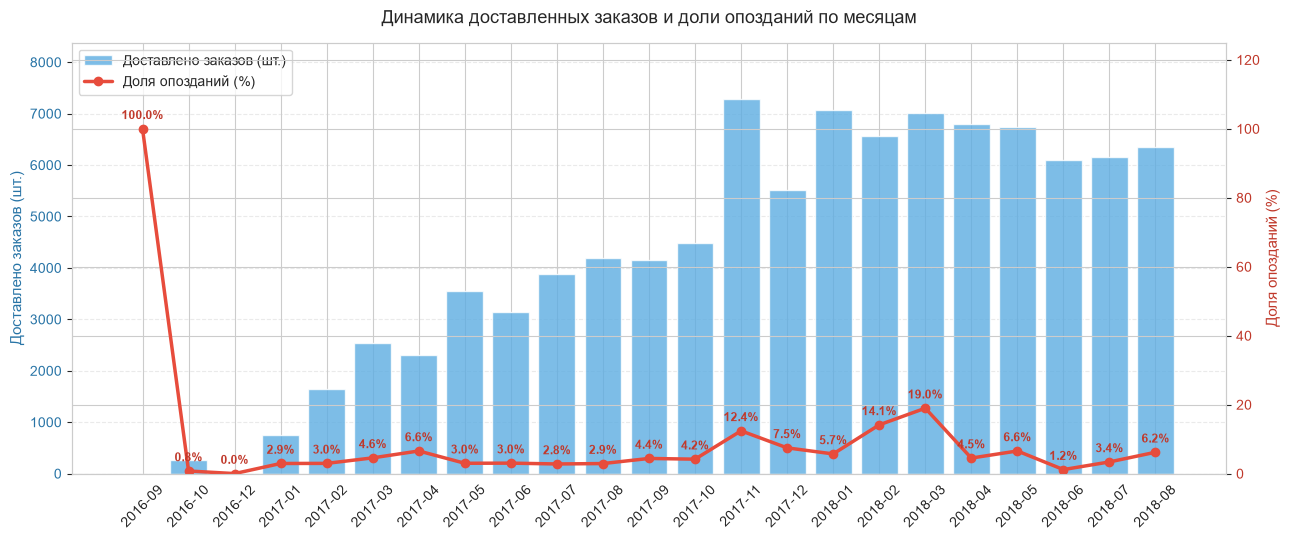

In [26]:
import matplotlib.pyplot as plt

# 1. Считаем статистику по месяцам прямо здесь
monthly_stats = (
    delivered_h.assign(
        purchase_month=delivered_h['order_purchase_timestamp']
        .dt.to_period('M')
        .astype(str)
    )
    .groupby('purchase_month')
    .agg(
        delivered_count=('order_id', 'count'),
        late_rate_pct=('is_late', lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
)

# 2. Строим график по всем месяцам без фильтрации
fig, ax1 = plt.subplots(figsize=(13, 5.5))

ax1.bar(
    monthly_stats['purchase_month'],
    monthly_stats['delivered_count'],
    color='#5dade2',
    alpha=0.8,
    label='Доставлено заказов (шт.)',
)
ax1.set_ylabel('Доставлено заказов (шт.)', color='#2874a6', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#2874a6')
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(0, monthly_stats['delivered_count'].max() * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(
    monthly_stats['purchase_month'],
    monthly_stats['late_rate_pct'],
    color='#e74c3c',
    marker='o',
    linewidth=2.5,
    markersize=6,
    label='Доля опозданий (%)',
)
ax2.set_ylabel('Доля опозданий (%)', color='#c0392b', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#c0392b')
ax2.set_ylim(0, monthly_stats['late_rate_pct'].max() * 1.25)

for x, y in zip(
    monthly_stats['purchase_month'], monthly_stats['late_rate_pct']
):
  ax2.annotate(
      f'{y:.1f}%',
      xy=(x, y),
      xytext=(0, 7),
      textcoords='offset points',
      ha='center',
      fontsize=8.5,
      fontweight='bold',
      color='#c0392b',
  )

plt.title(
    'Динамика доставленных заказов и доли опозданий по месяцам',
    fontsize=13,
    pad=14,
)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper left',
    frameon=True,
    facecolor='white',
)

plt.tight_layout()
plt.show()

Виден рост доли опозданий в периоды:
- ноябрь 2017 наблюдается увеличение числа заказов и резкий рост доли опозданий.
- февраль-март 2018  при стабильном потоке заказов, доля опозданий достигла исторического максимума.
- 2016 год показывает выброс, но его не принимаем во внимание по причине малого количества заказов.

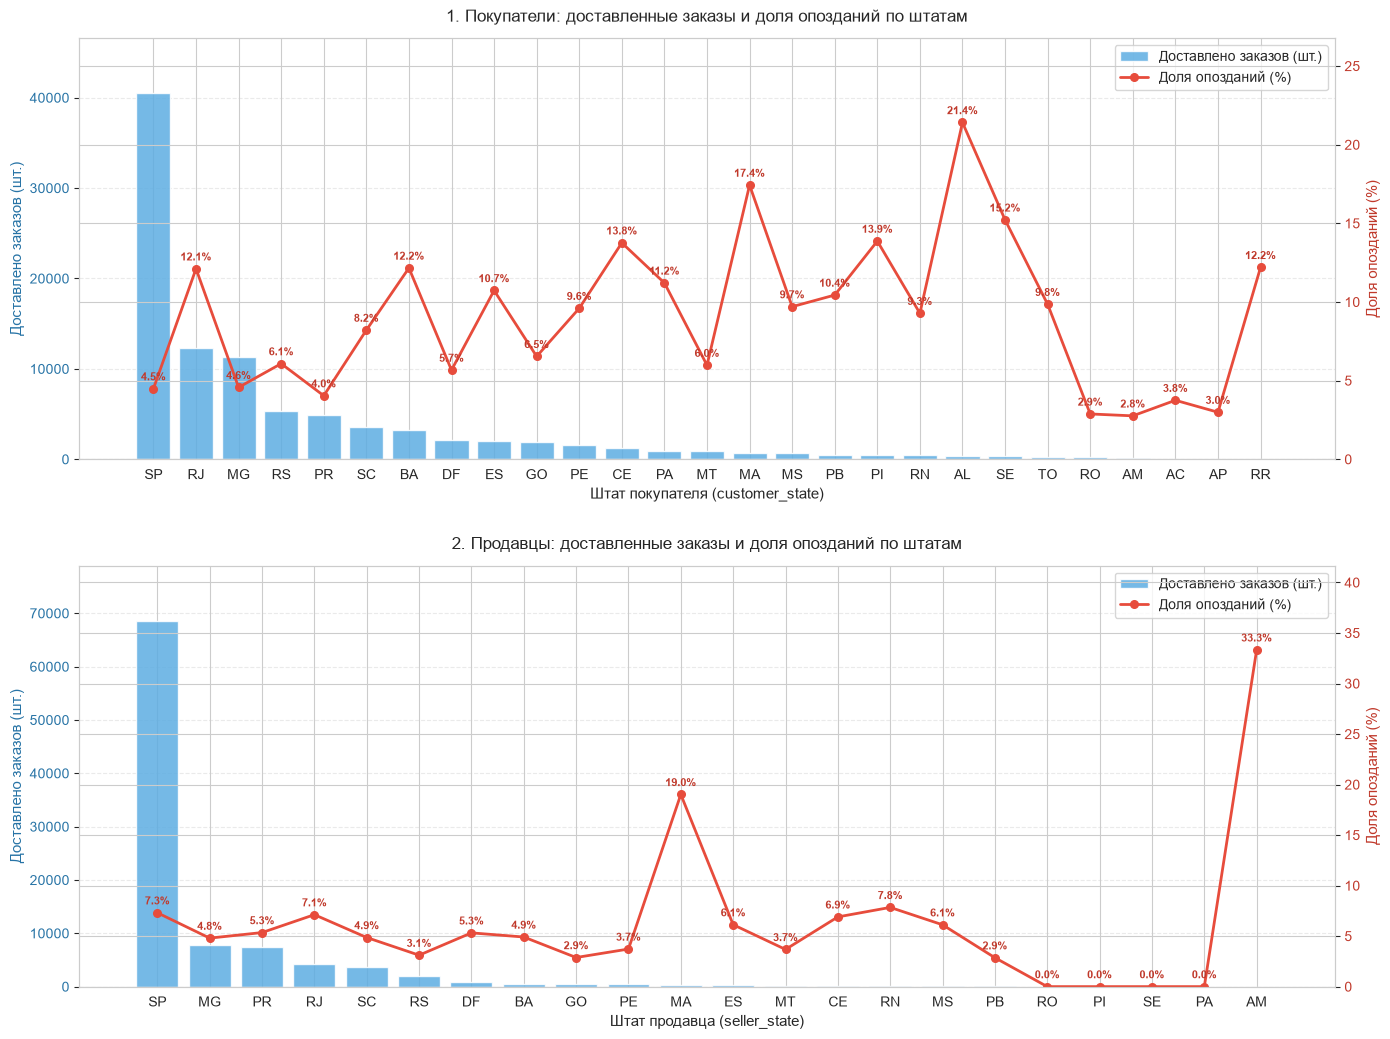

In [27]:
# 1. Агрегация по штатам ПОКУПАТЕЛЕЙ
cust_stats = (
    delivered_h.merge(
        df['customers'][['customer_id', 'customer_state']],
        on='customer_id',
        how='left',
    )
    .groupby('customer_state')
    .agg(
        delivered_count=('order_id', 'count'),
        late_rate_pct=('is_late', lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
    .rename(columns={'customer_state': 'state'})
    .sort_values('delivered_count', ascending=False)
)

# 2. Агрегация по штатам ПРОДАВЦОВ (уникальные заказы на штат)
sell_stats = (
    delivered_h[['order_id', 'is_late']]
    .merge(df['items'][['order_id', 'seller_id']], on='order_id', how='inner')
    .merge(
        df['sellers'][['seller_id', 'seller_state']],
        on='seller_id',
        how='left',
    )[['order_id', 'seller_state', 'is_late']]
    .drop_duplicates()
    .groupby('seller_state')
    .agg(
        delivered_count=('order_id', 'count'),
        late_rate_pct=('is_late', lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
    .rename(columns={'seller_state': 'state'})
    .sort_values('delivered_count', ascending=False)
)


# 3. Функция отрисовки одного комбо-графика (столбцы + линия)
def plot_state_combo(ax1, data, title, xlabel):
  ax1.bar(
      data['state'],
      data['delivered_count'],
      color='#5dade2',
      alpha=0.85,
      label='Доставлено заказов (шт.)',
  )
  ax1.set_ylabel('Доставлено заказов (шт.)', color='#2874a6', fontsize=10.5)
  ax1.tick_params(axis='y', labelcolor='#2874a6')
  ax1.set_xlabel(xlabel, fontsize=10.5)
  ax1.set_ylim(0, data['delivered_count'].max() * 1.15)
  ax1.grid(axis='y', linestyle='--', alpha=0.4)

  ax2 = ax1.twinx()
  ax2.plot(
      data['state'],
      data['late_rate_pct'],
      color='#e74c3c',
      marker='o',
      linewidth=2,
      markersize=5.5,
      label='Доля опозданий (%)',
  )
  ax2.set_ylabel('Доля опозданий (%)', color='#c0392b', fontsize=10.5)
  ax2.tick_params(axis='y', labelcolor='#c0392b')
  ax2.set_ylim(0, data['late_rate_pct'].max() * 1.25)

  for x, y in zip(data['state'], data['late_rate_pct']):
    ax2.annotate(
        f'{y:.1f}%',
        xy=(x, y),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        fontsize=8,
        fontweight='bold',
        color='#c0392b',
    )

  ax1.set_title(title, fontsize=12.5, pad=12)
  lines_1, labels_1 = ax1.get_legend_handles_labels()
  lines_2, labels_2 = ax2.get_legend_handles_labels()
  ax1.legend(
      lines_1 + lines_2,
      labels_1 + labels_2,
      loc='upper right',
      frameon=True,
      facecolor='white',
  )


# 4. Создаём полотно из 2 графиков друг под другом
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(14, 10.5))

plot_state_combo(
    ax_top,
    cust_stats,
    '1. Покупатели: доставленные заказы и доля опозданий по штатам',
    'Штат покупателя (customer_state)',
)

plot_state_combo(
    ax_bottom,
    sell_stats,
    '2. Продавцы: доставленные заказы и доля опозданий по штатам',
    'Штат продавца (seller_state)',
)

plt.tight_layout(h_pad=2.5)
plt.show()

Количество заказов распределено между штатами неравномерно, доля опозданий сильно разнится от штата к штату, наиболее высокие показатели в отдаленных малонаселенных регионах.

Посмотрим на оценки опоздавших и своевременных заказов:

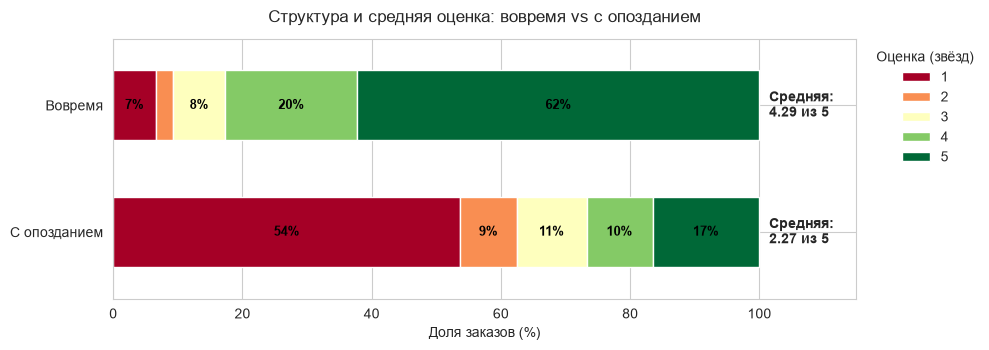

In [28]:

# 1. Собираем таблицу df_vis с оценками и статусом доставки
reviews_agg = (
    df['reviews']
    .groupby('order_id')
    .agg(review_score=('review_score', 'mean'))
    .reset_index()
)

df_vis = delivered_h[['order_id', 'is_late']].merge(
    reviews_agg, on='order_id', how='inner'
)
df_vis['status_label'] = df_vis['is_late'].map(
    {0: 'Вовремя', 1: 'С опозданием'}
)
df_vis['score_round'] = df_vis['review_score'].round().astype(int)

# 2. Считаем доли оценок по группам (в %)
score_ct = (
    pd.crosstab(df_vis['status_label'], df_vis['score_round'], normalize='index')
    * 100
)
order = ['С опозданием', 'Вовремя']
score_ct = score_ct.reindex([row for row in order if row in score_ct.index])

# 3. Считаем среднюю оценку для каждой группы
means = df_vis.groupby('status_label')['review_score'].mean()

# 4. Строим горизонтальный Stacked Bar
ax = score_ct.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 3.6),
    colormap='RdYlGn',  # от красного (1 звезда) к зелёному (5 звёзд)
    width=0.55,
)

plt.title(
    'Структура и средняя оценка: вовремя vs с опозданием', fontsize=12, pad=12
)
plt.xlabel('Доля заказов (%)')
plt.ylabel('')
plt.xlim(0, 115)
plt.legend(
    title='Оценка (звёзд)',
    bbox_to_anchor=(1.01, 1),
    loc='upper left',
    frameon=False,
)

# Подписываем доли (%) внутри сегментов шире 6%
for c in ax.containers:
  labels = [f'{v:.0f}%' if v > 6 else '' for v in c.datavalues]
  ax.bar_label(
      c,
      labels=labels,
      label_type='center',
      fontsize=9.5,
      fontweight='bold',
      color='black',
  )

# Добавляем среднюю оценку справа от каждой полосы (без символа ★, чтобы не было UserWarning)
for i, status in enumerate(score_ct.index):
  mean_val = means[status]
  ax.text(
      101.5,
      i,
      f'Средняя:\n{mean_val:.2f} из 5',
      va='center',
      ha='left',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()
plt.show()

Оценки для заказов с опозданием значительно ниже в сравнении с доставленными вовремя.

**Гипотезы и дальнейшие шаги**

**Основной вопрос задачи**

Какие факторы влияют на вероятность своевременной доставки заказа? Как можно было бы ее повысить?

**Гипотезы для проверки**

Гипотеза 1. влияют ли на своевременность доставки географические факторы - Анастасия, Иван
- расстояние между продавцом и покупателем по координатам
- штат и город покупателя и продавца
- доставка внутри одного штата или в другой штат

Гипотеза 2. влияют ли на своевременность доставки характеристики продавца - Александра
- задержка передачи заказа перевозчику относительно срока отгрузки
- доля опозданий у каждого продавца
- продавцы которые систематически отправляют заказы позже срока
- число заказов у продавца (продавцов с малым числом заказов не учитываем?) штат продавца?

Гипотеза 3. влияют ли на своевременность доставки характеристики заказа - Дарья, Алина
- вес и размеры товара
- объем и вес посылки в заказе
- число товаров в заказе
- категория товара
- стоимость доставки

# Проверка гипотезы 1. Удалённость продавца от места доставки

Проверяем гипотезу 1 из плана выше: **«На время доставки влияет удалённость продавца от места доставки: чем меньше расстояние доставки, тем вероятнее доставка вовремя»**.

**Метрики и дизайн проверки:**
- **Основной целевой показатель:** `is_late` — доля опоздавших заказов (календарная дата получения позже обещанной календарной даты).
- **Дополнительные метрики сроков:** `delivery_days` (фактический срок), `promised_days` (обещанный срок), `transit_days` (время в пути от перевозчика до покупателя), `carrier_days` (сборка до передачи перевозчику), `delay_days` (отклонение факта от плана).
- **Единица наблюдения:** один доставленный заказ (1 строка = 1 `order_id`).
- **Подгипотезы:**
  - **1.1.** Чем больше расстояние `distance_km`, тем дольше фактическая доставка и выше доля опозданий.
  - **1.2.** Межштатная доставка (`same_state == 0`) и доставка в другой город (`same_city == 0`) опаздывают чаще локальной; доля опозданий различается по штатам покупателей и ключевым коридорам.
- **Рабочий порог практической значимости:** разница от **2 п.п.** и выше.

## 1. Целевой признак опоздания и метрики сроков (на базе `dl`)

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)
pd.set_option('display.max_columns', 30)

delivered_h = dl[dl['order_delivered_customer_date'].notna()].copy()

# Признак опоздания по календарным датам
delivered_h['is_late'] = (
   delivered_h['order_delivered_customer_date'].dt.normalize() >
   delivered_h['order_estimated_delivery_date'].dt.normalize()
).astype(int)
delivered_h['is_on_time'] = 1 -delivered_h['is_late']

# Временные метрики (в днях)
delivered_h['delivery_days'] = (
   delivered_h['order_delivered_customer_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['promised_days'] = (
   delivered_h['order_estimated_delivery_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['delay_days'] = (
   delivered_h['order_delivered_customer_date'].dt.normalize() -
   delivered_h['order_estimated_delivery_date'].dt.normalize()
).dt.days
delivered_h['carrier_days'] = (
   delivered_h['order_delivered_carrier_date'] -delivered_h['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_h['transit_days'] = (
   delivered_h['order_delivered_customer_date'] -delivered_h['order_delivered_carrier_date']
).dt.total_seconds() / 86400

# Отрицательные длительности заменяем на NaN
for col in ['carrier_days', 'transit_days']:
   delivered_h.loc[delivered_h[col] < 0, col] = np.nan

delivered_h['purchase_year'] =delivered_h['order_purchase_timestamp'].dt.year
delivered_h['purchase_month'] =delivered_h['order_purchase_timestamp'].dt.to_period('M').astype(str)

print('Доставленных заказов с датой доставки:', len(delivered_h))
print('Опоздало заказов:',delivered_h['is_late'].sum())
print('Доля опозданий, %:', round(delivered_h['is_late'].mean() * 100, 2))
print('Доля доставленных вовремя (OTD), %:', round(delivered_h['is_on_time'].mean() * 100, 2))


Доставленных заказов с датой доставки: 96470
Опоздало заказов: 6534
Доля опозданий, %: 6.77
Доля доставленных вовремя (OTD), %: 93.23


## 2. Расчёт расстояний и сборка витрины заказа

Используем уже собранные выше таблицы:
1. Отсеиваем выбросы координат за пределами Бразилии и присоединяем медианные координаты к `df_customers`.
2. Расстояние по прямой между продавцом и покупателем считаем по **формуле гаверсинуса (Haversine)** ($R = 6371$ км):
   $$d = 2R \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta\phi}{2}\right) + \cos(\phi_1)\cos(\phi_2)\sin^2\left(\frac{\Delta\lambda}{2}\right)}\right)$$
Чтобы приблизить расстояние «по прямой» к реальному автодорожному без сложных расчетов, в логистике часто умножают результат гаверсинуса на коэффициент извилистости дорог, для Бразилии обычно берут 1.2 – 1.3. Возьмем для расчетов параметр circuity_factor=1.25
3. Сводим `df_orders_products` к уровню заказа (1 строка = 1 `order_id`): при наличии нескольких продавцов в заказе берём **максимальное расстояние** (оно лимитирует доставку всего заказа) и дополнительно фиксируем `n_sellers`, `same_state` и `same_city`.

In [30]:
# 1. Фильтруем уже агрегированные координаты от выбросов за пределами Бразилии
geo_clean = df_geo_avg_code[
    df_geo_avg_code['geolocation_lat'].between(-33.8, 5.3) &
    df_geo_avg_code['geolocation_lng'].between(-74.0, -34.7)
]

sellers_geo = df_sellers_geo[
    ['seller_id', 'seller_city', 'seller_state', 'geolocation_lat', 'geolocation_lng']
].copy()
bad_seller_geo = ~(
    sellers_geo['geolocation_lat'].between(-33.8, 5.3) &
    sellers_geo['geolocation_lng'].between(-74.0, -34.7)
)
sellers_geo.loc[bad_seller_geo, ['geolocation_lat', 'geolocation_lng']] = np.nan
sellers_geo = sellers_geo.rename(columns={'geolocation_lat': 'seller_lat', 'geolocation_lng': 'seller_lng'})

# Присоединяем координаты к покупателям
customers_geo = df_customers.merge(
    geo_clean, how='left',
    left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix'
).rename(columns={'geolocation_lat': 'customer_lat', 'geolocation_lng': 'customer_lng'}).drop(columns='geolocation_zip_code_prefix')


# 2. Функция расчёта расстояния по формуле гаверсинуса (км)
def haversine_km(lat1, lon1, lat2, lon2, circuity_factor=1.25):
    r = 6371.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0) ** 2
    straight_distance = 2.0 * r * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))
    return straight_distance * circuity_factor



# 3. Берём позиции доставленных заказов из уже объединённой df_orders_products
items_h1 = (
    df_orders_products.loc[
        df_orders_products['order_id'].isin(delivered_h['order_id']) &
        df_orders_products['order_item_id'].notna(),
        ['order_id', 'customer_id', 'order_item_id', 'seller_id', 'price', 'freight_value', 'product_weight_g']
    ]
    .merge(customers_geo[['customer_id', 'customer_city', 'customer_state', 'customer_lat', 'customer_lng']],
           how='left', on='customer_id')
    .merge(sellers_geo, how='left', on='seller_id')
)

items_h1['weight_g'] = items_h1['product_weight_g'].replace(0, np.nan)
items_h1['item_distance_km'] = haversine_km(
    items_h1['seller_lat'], items_h1['seller_lng'],
    items_h1['customer_lat'], items_h1['customer_lng'],
    circuity_factor=1.25
)
items_h1['item_same_state'] = (items_h1['seller_state'] == items_h1['customer_state']).astype(int)
items_h1['item_same_city'] = (
    (items_h1['seller_state'] == items_h1['customer_state']) &
    (items_h1['seller_city'].str.strip().str.lower() == items_h1['customer_city'].str.strip().str.lower())
).astype(int)

# 4. Сводим к 1 строке на заказ (order_id)
order_geo_features = items_h1.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    n_sellers=('seller_id', 'nunique'),
    distance_km=('item_distance_km', 'max'),
    same_state=('item_same_state', 'min'),   # 1, только если все продавцы в штате покупателя
    same_city=('item_same_city', 'min'),     # 1, только если все продавцы в городе покупателя
    price_total=('price', 'sum'),
    freight_total=('freight_value', 'sum'),
    weight_sum=('weight_g', 'sum'),
    weight_known=('weight_g', 'count'),
).reset_index()

order_geo_features.loc[
    order_geo_features['weight_known'] < order_geo_features['n_items'], 'weight_sum'
] = np.nan
order_geo_features['weight_kg'] = order_geo_features['weight_sum'] / 1000

# Основной продавец заказа (самый удалённый, при равенстве — самый дорогой товар)
main_seller = (
    items_h1.sort_values(['order_id', 'item_distance_km', 'price'], ascending=[True, False, False])
    .drop_duplicates('order_id')[['order_id', 'seller_id', 'seller_state', 'seller_city']]
)

# Итоговая витрина для проверки гипотезы 1
data_h1 = (
   delivered_h
    .merge(order_geo_features, how='left', on='order_id')
    .merge(main_seller, how='left', on='order_id')
    .merge(df_customers[['customer_id', 'customer_state', 'customer_city']], how='left', on='customer_id')
)

assert len(data_h1) == len(delivered_h), 'Строки размножились при объединении!'
assert data_h1['order_id'].is_unique, 'order_id перестал быть уникальным!'

data_h1['geo_zone'] = np.where(
    data_h1['same_city'] == 1, 'Внутри города',
    np.where(data_h1['same_state'] == 1, 'Внутри штата\n(другой город)', 'В другой штат')
)
data_h1['route'] = data_h1['seller_state'] + ' → ' + data_h1['customer_state']

print('Строк в витрине data_h1:', len(data_h1), '| order_id уникален:', data_h1['order_id'].is_unique)
print('Заказов с несколькими продавцами, %:', round((data_h1['n_sellers'] > 1).mean() * 100, 2))
print('Заказов без координат (distance_km = NaN):', data_h1['distance_km'].isna().sum(),
      f"({data_h1['distance_km'].isna().mean() * 100:.2f}%)")

Строк в витрине data_h1: 96470 | order_id уникален: True
Заказов с несколькими продавцами, %: 1.32
Заказов без координат (distance_km = NaN): 480 (0.50%)


## 3. Основные показатели расстояния и сроков доставки

Смотрим описательные статистики для непрерывных переменных. Из-за скошенности распределений ориентируемся прежде всего на медиану и перцентили.

In [31]:
desc_cols = ['distance_km', 'delivery_days', 'promised_days', 'transit_days', 'carrier_days', 'freight_total']
display(data_h1[desc_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

,distance_km,delivery_days,promised_days,transit_days,carrier_days,freight_total
count,95990.00,96470.00,96470.00,96446.00,96304.00,96470.00
mean,752.21,12.56,23.74,9.33,3.23,22.79
std,740.86,9.55,8.76,8.76,3.55,21.56
min,0.00,0.53,2.01,0.00,0.00,0.00
25%,235.74,6.77,18.33,4.10,1.13,13.85
50%,544.38,10.22,23.23,7.10,2.21,17.17
75%,1000.19,15.72,28.41,12.03,4.07,24.02
90%,1821.69,23.10,34.29,18.90,6.41,39.38
95%,2620.34,29.27,38.42,24.21,8.88,54.78
99%,3103.85,46.05,50.21,40.99,17.75,104.25


## 4. Распределение расстояния доставки

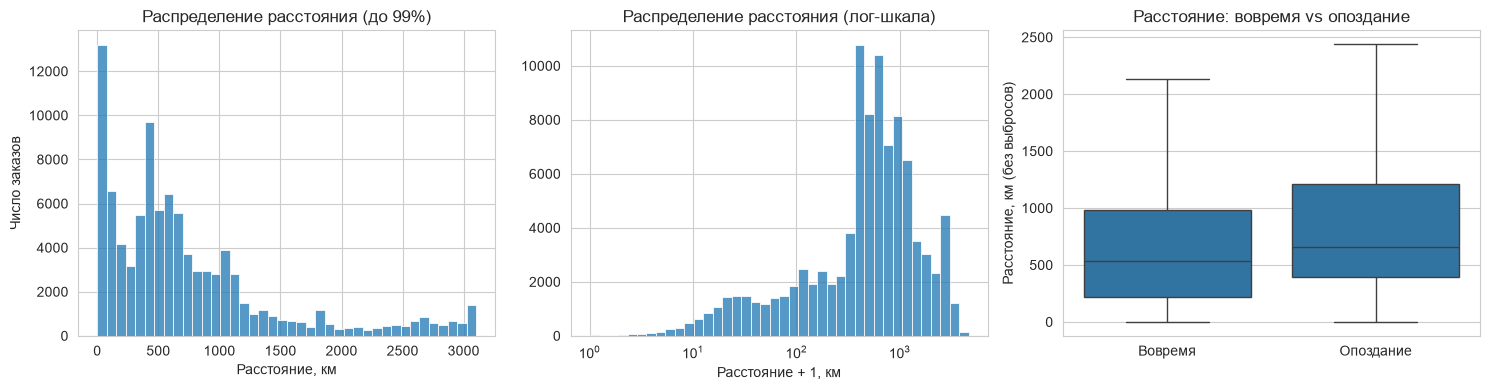

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

d_valid = data_h1['distance_km'].dropna()

# 1) Гистограмма (обрезана по 99-му перцентилю)
sns.histplot(d_valid.clip(upper=d_valid.quantile(0.99)), bins=40, ax=ax[0])
ax[0].set_title('Распределение расстояния (до 99%)')
ax[0].set_xlabel('Расстояние, км')
ax[0].set_ylabel('Число заказов')

# 2) Логарифмическая шкала (добавляем 1 км, чтобы учесть нулевые расстояния внутри индекса)
sns.histplot(d_valid + 1, bins=40, log_scale=True, ax=ax[1])
ax[1].set_title('Распределение расстояния (лог-шкала)')
ax[1].set_xlabel('Расстояние + 1, км')
ax[1].set_ylabel('')

# 3) Сравнение расстояний: вовремя vs опоздание
d_plot = data_h1.dropna(subset=['distance_km']).copy()
d_plot['статус'] = d_plot['is_late'].map({0: 'Вовремя', 1: 'Опоздание'})
sns.boxplot(data=d_plot, x='статус', y='distance_km', showfliers=False, ax=ax[2])
ax[2].set_title('Расстояние: вовремя vs опоздание')
ax[2].set_xlabel('')
ax[2].set_ylabel('Расстояние, км (без выбросов)')

plt.tight_layout()
plt.show()

## 5. Как сравниваем группы (95% ДИ Уилсона и графики)

Используем функции расчёта доли опозданий с 95% доверительным интервалом по методу Уилсона.

In [33]:
def wilson_ci(k, n, z=1.96):
    # 95% доверительный интервал для доли (метод Уилсона)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def late_by_group_h1(df, group):
    t = df.groupby(group, observed=True)['is_late'].agg(['size', 'sum'])
    t.columns = ['заказов', 'опоздало']
    t['доля опозданий, %'] = t['опоздало'] / t['заказов'] * 100
    t['OTD (вовремя), %'] = 100 - t['доля опозданий, %']
    ci = [wilson_ci(k, n) for k, n in zip(t['опоздало'], t['заказов'])]
    t['ДИ от, %'] = [c[0] * 100 for c in ci]
    t['ДИ до, %'] = [c[1] * 100 for c in ci]
    return t

def plot_late_h1(t, title, xlabel, base_rate=None):
    if base_rate is None:
        base_rate = data_h1['is_late'].mean() * 100
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    x = range(len(t))
    ax.bar(x, t['доля опозданий, %'], color='tab:blue', alpha=0.8)
    err = [t['доля опозданий, %'] - t['ДИ от, %'], t['ДИ до, %'] - t['доля опозданий, %']]
    ax.errorbar(x, t['доля опозданий, %'], yerr=err, fmt='none', ecolor='black', capsize=4)
    ax.axhline(base_rate, color='red', linestyle='--', label=f'все заказы ({base_rate:.1f}%)')
    for i, (v, top) in enumerate(zip(t['доля опозданий, %'], t['ДИ до, %'])):
        ax.text(i, top + 0.25, f'{v:.1f}'.replace('.', ',') + '%', ha='center', fontsize=9)
    ax.set_ylim(0, max(t['ДИ до, %'].max() * 1.15, t['ДИ до, %'].max() + 2.0))
    ax.set_xticks(list(x))
    ax.set_xticklabels(t.index, rotation=0, ha='center')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Доля опоздавших заказов, %')
    ax.legend()
    plt.tight_layout()
    plt.show()

## 6. Доля опозданий по расстоянию доставки

Разбиваем `distance_km` двумя способами:
1. По понятным бизнес-интервалам (от локальной доставки до 50 км до сверхдальней более 2000 км).
2. На 5 равных по числу заказов групп (квинтили), чтобы исключить эффект разного размера корзин.

,заказов,опоздало,"доля опозданий, %","OTD (вовремя), %","ДИ от, %","ДИ до, %"
dist_group,,,,,,
до 50,10315,455,4.41,95.59,4.03,4.82
50-200,12250,571,4.66,95.34,4.30,5.05
200-500,22158,1414,6.38,93.62,6.07,6.71
500-1000,27261,1896,6.95,93.05,6.66,7.26
1000-2000,15871,1194,7.52,92.48,7.12,7.94
более 2000,8135,959,11.79,88.21,11.11,12.51


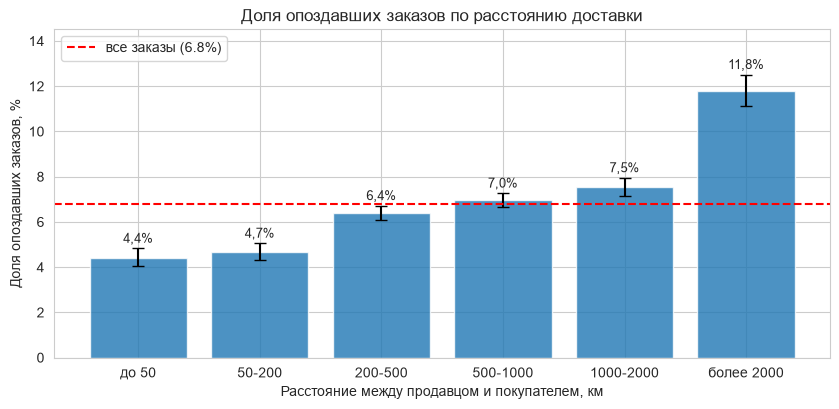

In [34]:
# 6.1. Бизнес-интервалы расстояний
d_bins = [-0.01, 50, 200, 500, 1000, 2000, np.inf]
d_labels = ['до 50', '50-200', '200-500', '500-1000', '1000-2000', 'более 2000']
data_h1['dist_group'] = pd.cut(data_h1['distance_km'], bins=d_bins, labels=d_labels)

t_dist = late_by_group_h1(data_h1.dropna(subset=['dist_group']), 'dist_group')
display(t_dist.round(2))
plot_late_h1(t_dist, 'Доля опоздавших заказов по расстоянию доставки', 'Расстояние между продавцом и покупателем, км')

,заказов,опоздало,"доля опозданий, %","OTD (вовремя), %","ДИ от, %","ДИ до, %"
dist_quintile,,,,,,
0-147 км,19198,876,4.56,95.44,4.28,4.87
147-436 км,19198,1116,5.81,94.19,5.49,6.15
436-664 км,19198,1265,6.59,93.41,6.25,6.95
664-1097 км,19198,1378,7.18,92.82,6.82,7.55
1097-4638 км,19198,1854,9.66,90.34,9.25,10.08


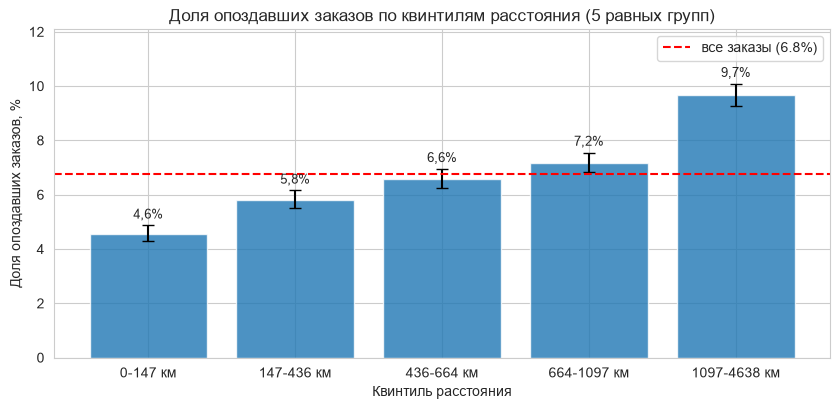

In [35]:
# 6.2. 5 равных по числу заказов групп (квинтили расстояния)
d_non_na = data_h1.dropna(subset=['distance_km']).copy()
q_edges = d_non_na['distance_km'].quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]).round(0).astype(int).tolist()
q_labels = [f'{q_edges[i]}-{q_edges[i + 1]} км' for i in range(5)]
data_h1['dist_quintile'] = pd.qcut(data_h1['distance_km'], 5, labels=q_labels)

t_quint = late_by_group_h1(data_h1.dropna(subset=['dist_quintile']), 'dist_quintile')
display(t_quint.round(2))
plot_late_h1(t_quint, 'Доля опоздавших заказов по квинтилям расстояния (5 равных групп)', 'Квинтиль расстояния')

## 7. Доля опозданий: внутри города, внутри штата и в другой штат

,заказов,опоздало,"доля опозданий, %","OTD (вовремя), %","ДИ от, %","ДИ до, %","медиана расстояния, км","медиана срока, дней"
geo_zone,,,,,,,,
Внутри города,4900,212,4.33,95.67,3.79,4.93,15.55,4.72
Внутри штата\n(другой город),29675,1351,4.55,95.45,4.32,4.80,158.98,6.96
В другой штат,61895,4971,8.03,91.97,7.82,8.25,822.67,12.78


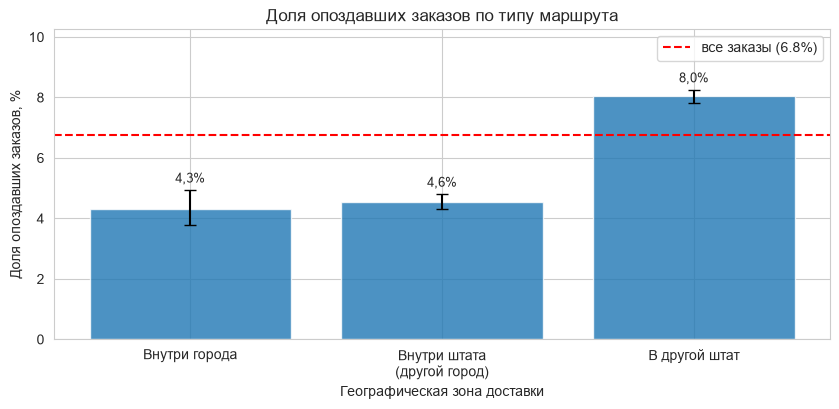

In [36]:
zone_order = ['Внутри города', 'Внутри штата\n(другой город)', 'В другой штат']
data_h1['geo_zone'] = pd.Categorical(data_h1['geo_zone'], categories=zone_order, ordered=True)

t_zone = late_by_group_h1(data_h1, 'geo_zone')
t_zone['медиана расстояния, км'] = data_h1.groupby('geo_zone', observed=True)['distance_km'].median()
t_zone['медиана срока, дней'] = data_h1.groupby('geo_zone', observed=True)['delivery_days'].median()

display(t_zone.round(2))
plot_late_h1(t_zone, 'Доля опоздавших заказов по типу маршрута', 'Географическая зона доставки')

## 8. Доля опозданий по штатам покупателей и ключевым коридорам доставки

Как и при анализе категорий в `04_volume.ipynb`, для сравнения оставляем штаты с **300 и более заказов**, чтобы исключить шум на малых выборках. Проверяем, объясняется ли разброс между штатами именно расстоянием (корреляция Спирмена между медианным расстоянием и долей опозданий по штатам).

Всего штатов покупателей: 27
Штатов в сравнении: 21
Доля заказов в этих штатах, %: 99.1


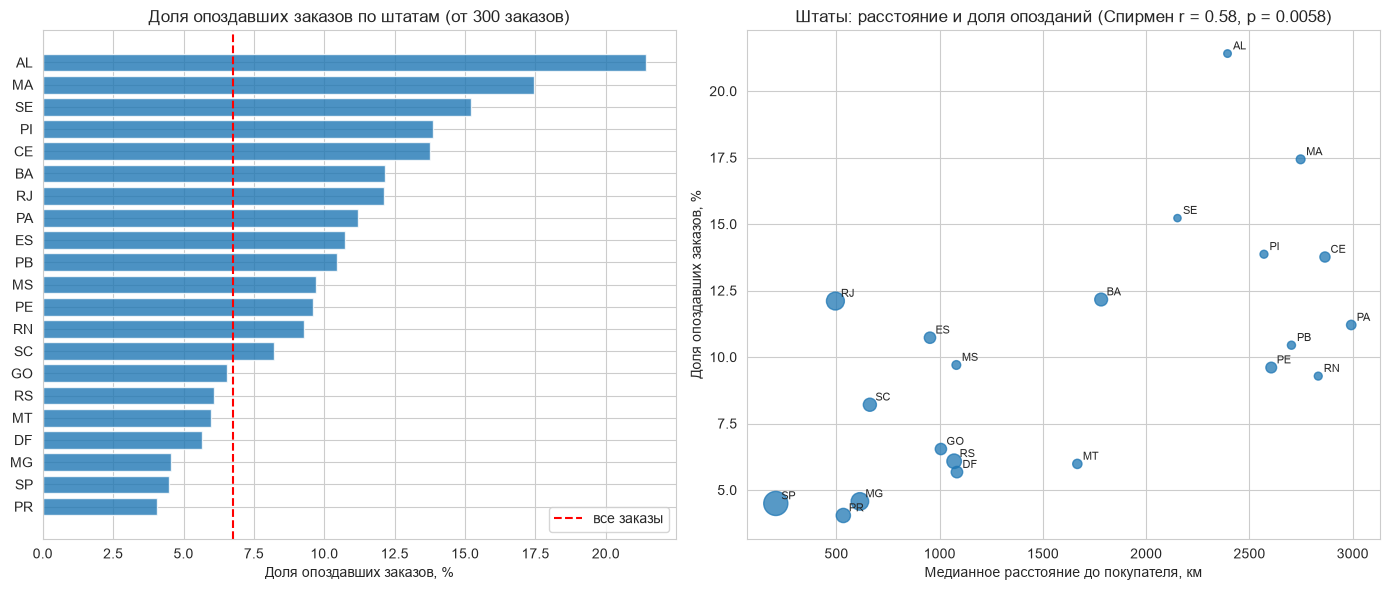


Топ-15 коридоров доставки по числу заказов:


,заказов,"доля опозданий, %","медиана расстояния, км","медиана срока, дней"
route,,,,
SP → SP,30671,4.66,118.84,6.55
SP → RJ,8159,14.12,480.04,12.84
SP → MG,7438,5.28,611.07,10.79
SP → RS,3603,6.61,1084.53,13.88
SP → PR,3122,4.42,524.22,11.09
PR → SP,2944,3.06,586.78,9.43
MG → SP,2555,3.56,584.11,9.21
SP → SC,2331,9.52,679.62,13.85
SP → BA,2310,12.86,1810.34,17.66


In [37]:
state_counts = data_h1['customer_state'].value_counts()
big_states = state_counts[state_counts >= 300].index.tolist()
if len(big_states) < 2:
    big_states = state_counts.index.tolist()

print('Всего штатов покупателей:', len(state_counts))
print('Штатов в сравнении:', len(big_states))
print('Доля заказов в этих штатах, %:', round(data_h1['customer_state'].isin(big_states).mean() * 100, 1))

state_table = (
    data_h1[data_h1['customer_state'].isin(big_states)]
    .groupby('customer_state')
    .agg(
        заказов=('order_id', 'count'),
        доля_опозданий=('is_late', lambda s: s.mean() * 100),
        медиана_км=('distance_km', 'median'),
        медиана_дней=('delivery_days', 'median'),
    )
    .sort_values('доля_опозданий')
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Левый график: доля опозданий по штатам
ax[0].barh(state_table.index, state_table['доля_опозданий'], color='tab:blue', alpha=0.8)
ax[0].axvline(data_h1['is_late'].mean() * 100, color='red', linestyle='--', label='все заказы')
ax[0].set_title('Доля опоздавших заказов по штатам (от 300 заказов)')
ax[0].set_xlabel('Доля опоздавших заказов, %')
ax[0].legend()

# Правый график: связь медианного расстояния штата и доли опозданий
rho_st, p_st = stats.spearmanr(state_table['медиана_км'], state_table['доля_опозданий'])
ax[1].scatter(state_table['медиана_км'], state_table['доля_опозданий'], s=np.sqrt(state_table['заказов']) * 1.5, alpha=0.75)
for st, row in state_table.iterrows():
    ax[1].annotate(st, (row['медиана_км'], row['доля_опозданий']), xytext=(4, 3), textcoords='offset points', fontsize=8)
ax[1].set_title(f'Штаты: расстояние и доля опозданий (Спирмен r = {rho_st:.2f}, p = {p_st:.4f})')
ax[1].set_xlabel('Медианное расстояние до покупателя, км')
ax[1].set_ylabel('Доля опоздавших заказов, %')

plt.tight_layout()
plt.show()

# Топ-15 самых крупных логистических коридоров (штат продавца -> штат покупателя)
routes_top = (
    data_h1.groupby('route')
    .agg(
        заказов=('order_id', 'count'),
        доля_опозданий_проц=('is_late', lambda s: s.mean() * 100),
        медиана_км=('distance_km', 'median'),
        медиана_дней=('delivery_days', 'median'),
    )
    .sort_values('заказов', ascending=False)
    .head(15)
)
routes_top.columns = ['заказов', 'доля опозданий, %', 'медиана расстояния, км', 'медиана срока, дней']
print('\nТоп-15 коридоров доставки по числу заказов:')
display(routes_top.round(2))

## 9. Обещанный срок, фактический срок, время в пути и запас времени по расстоянию

Этот шаг отвечает на ключевой бизнес-вопрос: **почему на дальних маршрутах (или на отдельных дистанциях) растёт доля опозданий — из-за долгой сборки продавцом, долгого пути перевозчика или недостаточного запаса в обещанной дате Olist?**

,"обещанный срок, дней","фактический срок, дней","передача перевозчику, дней","время в пути, дней","запас, дней","доля опозданий, %"
dist_group,,,,,,
до 50,14.7,6.1,3.1,3.0,8.6,4.41
50-200,17.0,7.6,3.2,4.4,9.4,4.66
200-500,23.3,11.8,3.2,8.6,11.5,6.38
500-1000,25.2,13.5,3.2,10.2,11.7,6.95
1000-2000,28.4,15.9,3.3,12.6,12.5,7.52
более 2000,32.7,20.7,3.4,17.3,12.0,11.79


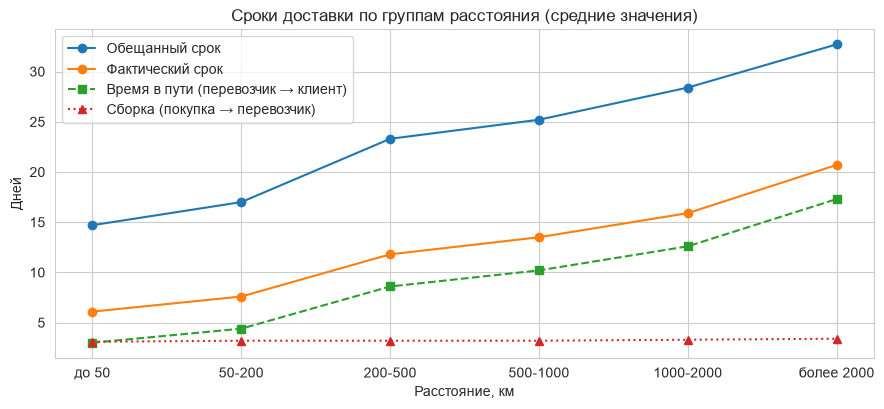

In [38]:
days_by_dist = (
    data_h1.dropna(subset=['dist_group'])
    .groupby('dist_group', observed=True)[['promised_days', 'delivery_days', 'carrier_days', 'transit_days']]
    .mean()
    .round(1)
)
days_by_dist['запас, дней'] = (days_by_dist['promised_days'] - days_by_dist['delivery_days']).round(1)
days_by_dist['доля опозданий, %'] = (
    data_h1.dropna(subset=['dist_group']).groupby('dist_group', observed=True)['is_late'].mean() * 100
).round(2)
days_by_dist.columns = [
    'обещанный срок, дней',
    'фактический срок, дней',
    'передача перевозчику, дней',
    'время в пути, дней',
    'запас, дней',
    'доля опозданий, %',
]
display(days_by_dist)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(days_by_dist))
ax.plot(x, days_by_dist['обещанный срок, дней'], marker='o', label='Обещанный срок')
ax.plot(x, days_by_dist['фактический срок, дней'], marker='o', label='Фактический срок')
ax.plot(x, days_by_dist['время в пути, дней'], marker='s', linestyle='--', label='Время в пути (перевозчик → клиент)')
ax.plot(x, days_by_dist['передача перевозчику, дней'], marker='^', linestyle=':', label='Сборка (покупка → перевозчик)')
ax.set_xticks(x)
ax.set_xticklabels(days_by_dist.index, rotation=0, ha='center')
ax.set_title('Сроки доставки по группам расстояния (средние значения)')
ax.set_xlabel('Расстояние, км')
ax.set_ylabel('Дней')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Корреляции между расстоянием, сроками, опозданием и контрольными факторами (Спирмен)

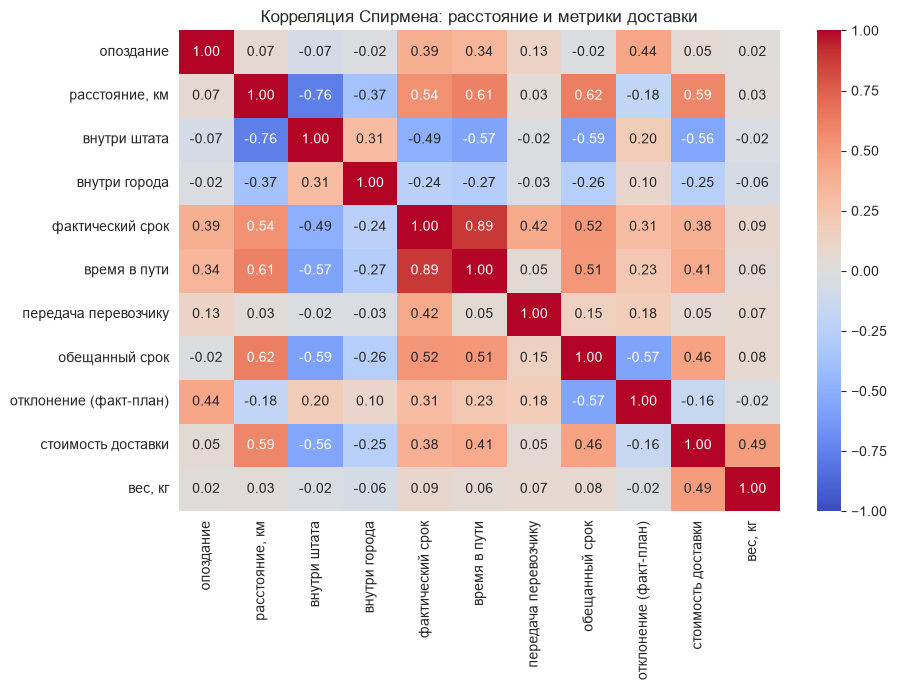

In [39]:
corr_cols_h1 = {
    'is_late': 'опоздание',
    'distance_km': 'расстояние, км',
    'same_state': 'внутри штата',
    'same_city': 'внутри города',
    'delivery_days': 'фактический срок',
    'transit_days': 'время в пути',
    'carrier_days': 'передача перевозчику',
    'promised_days': 'обещанный срок',
    'delay_days': 'отклонение (факт-план)',
    'freight_total': 'стоимость доставки',
    'weight_kg': 'вес, кг',
}
corr_h1 = data_h1[list(corr_cols_h1)].rename(columns=corr_cols_h1).corr(method='spearman')

plt.figure(figsize=(9.5, 7))
sns.heatmap(corr_h1, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляция Спирмена: расстояние и метрики доставки')
plt.tight_layout()
plt.show()

## 11. Статистическая проверка гипотез 1.1 и 1.2 и размер эффекта

Используем методы, подходящие для скошенных распределений и сильного дисбаланса классов (доля опозданий ~6,8%):
- **Тест Кохрана — Армитаджа на тренд (Cochran–Armitage trend test):** проверяет именно *направленный монотонный рост* доли опозданий по упорядоченным корзинам расстояния (в отличие от обычного $\chi^2$, который не учитывает порядок групп).
- **Хи-квадрат ($\chi^2$):** проверяет наличие любых различий между корзинами и между географическими зонами.
- **Критерий Манна — Уитни, ROC-AUC и Cliff's delta (рангово-бисериальная корреляция):** показывают, с какой вероятностью случайно взятый опоздавший заказ ехал дальше вовремя доставленного (для бинарного таргета с дисбалансом эти метрики интерпретируются гораздо точнее, чем $\rho$ Спирмена).
- **Корреляция Спирмена ($\rho$):** для непрерывных сроков (`delivery_days`, `transit_days`, `delay_days`).
- **Поправка Холма — Бонферрони:** корректировка $p$-value на множественные проверки.
- **Размер эффекта в п.п. с 95% ДИ:** сверяем величину различий с рабочим порогом **2 п.п.**

In [40]:
d_stat = data_h1.dropna(subset=['distance_km']).copy()

# --- Вспомогательные функции: тест Кохрана-Армитаджа на тренд, ROC-AUC / Cliff's delta, Холм-Бонферрони ---
def cochran_armitage_trend(df, ordered_group_col, binary_col='is_late', scores=None):
    """Двусторонний тест Кохрана-Армитаджа на линейный тренд доли по упорядоченным группам."""
    tab = df.groupby(ordered_group_col, observed=True)[binary_col].agg(['sum', 'size'])
    k = tab['sum'].to_numpy(dtype=float)
    n = tab['size'].to_numpy(dtype=float)
    if scores is None:
        t = np.arange(len(n), dtype=float)
    else:
        t = np.asarray(scores, dtype=float)
    N = n.sum()
    p_bar = k.sum() / N
    t_bar = np.sum(n * t) / N
    num = np.sum(k * (t - t_bar))
    var = p_bar * (1.0 - p_bar) * np.sum(n * (t - t_bar) ** 2)
    if var <= 0:
        return np.nan, np.nan
    z = num / np.sqrt(var)
    pval = 2.0 * stats.norm.sf(abs(z))
    return z, pval

def holm_bonferroni(pvals):
    """Поправка Холма-Бонферрони на множественные сравнения."""
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m, dtype=float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = pvals[idx] * (m - rank)
        running_max = max(running_max, val)
        adj[idx] = min(running_max, 1.0)
    return adj

# 11.1. Тесты для расстояния (гипотеза 1.1)
z_ca_dist, p_ca_dist = cochran_armitage_trend(d_stat, 'dist_group', 'is_late')
z_ca_quint, p_ca_quint = cochran_armitage_trend(d_stat, 'dist_quintile', 'is_late')
chi2_dist, p_chi_dist, _, _ = stats.chi2_contingency(pd.crosstab(d_stat['dist_group'], d_stat['is_late']))

late_km = d_stat.loc[d_stat['is_late'] == 1, 'distance_km']
ontime_km = d_stat.loc[d_stat['is_late'] == 0, 'distance_km']
mw_res = stats.mannwhitneyu(late_km, ontime_km, alternative='two-sided')
p_mw_dist = mw_res.pvalue
roc_auc_dist = mw_res.statistic / (len(late_km) * len(ontime_km))
cliffs_delta = 2.0 * roc_auc_dist - 1.0

rho_deliv, p_rho_deliv = stats.spearmanr(d_stat['distance_km'], d_stat['delivery_days'])
d_tr = d_stat.dropna(subset=['transit_days'])
rho_transit, p_rho_transit = stats.spearmanr(d_tr['distance_km'], d_tr['transit_days'])
rho_delay, p_rho_delay = stats.spearmanr(d_stat['distance_km'], d_stat['delay_days'])

# 11.2. Тесты для географических зон (гипотеза 1.2)
chi2_state, p_chi_state, _, _ = stats.chi2_contingency(pd.crosstab(data_h1['same_state'], data_h1['is_late']))
z_ca_zone, p_ca_zone = cochran_armitage_trend(data_h1, 'geo_zone', 'is_late')

summary_tests = pd.DataFrame([
    {'Проверка': 'Кохран–Армитадж (тренд): dist_group → is_late', 'Статистика / эффект': f'Z = {z_ca_dist:.2f}', 'p-value': p_ca_dist},
    {'Проверка': 'Кохран–Армитадж (тренд): dist_quintile → is_late', 'Статистика / эффект': f'Z = {z_ca_quint:.2f}', 'p-value': p_ca_quint},
    {'Проверка': 'Хи-квадрат: dist_group vs is_late', 'Статистика / эффект': f'χ² = {chi2_dist:.1f}', 'p-value': p_chi_dist},
    {'Проверка': 'Манна–Уитни: distance_km (опоздавшие vs вовремя)', 'Статистика / эффект': f'AUC = {roc_auc_dist:.3f}, Cliff δ = {cliffs_delta:+.3f}', 'p-value': p_mw_dist},
    {'Проверка': 'Спирмен: distance_km vs delivery_days (факт. срок)', 'Статистика / эффект': f'ρ = {rho_deliv:.3f}', 'p-value': p_rho_deliv},
    {'Проверка': 'Спирмен: distance_km vs transit_days (время в пути)', 'Статистика / эффект': f'ρ = {rho_transit:.3f}', 'p-value': p_rho_transit},
    {'Проверка': 'Спирмен: distance_km vs delay_days (факт - план)', 'Статистика / эффект': f'ρ = {rho_delay:.3f}', 'p-value': p_rho_delay},
    {'Проверка': 'Хи-квадрат: внутри штата vs другой штат', 'Статистика / эффект': f'χ² = {chi2_state:.1f}', 'p-value': p_chi_state},
    {'Проверка': 'Кохран–Армитадж (тренд): 3 гео-зоны → is_late', 'Статистика / эффект': f'Z = {z_ca_zone:.2f}', 'p-value': p_ca_zone},
])
summary_tests['p (Холм–Бонферрони)'] = holm_bonferroni(summary_tests['p-value'])
display(summary_tests.round({'p-value': 5, 'p (Холм–Бонферрони)': 5}))

print(f'Медианное расстояние у опоздавших: {late_km.median():.1f} км | у доставленных вовремя: {ontime_km.median():.1f} км')
print(f'Вероятность, что случайный опоздавший заказ ехал дальше вовремя доставленного (ROC-AUC): {roc_auc_dist:.3f} (Cliff δ = {cliffs_delta:+.3f})')

# 11.3. Размер разницы (эффект в п.п., 95% ДИ и поправка Холма-Бонферрони)
def diff_pp_ci(s_high, s_low, label):
    n1, n0 = len(s_high), len(s_low)
    k1, k0 = s_high.sum(), s_low.sum()
    p1, p0 = k1 / n1, k0 / n0
    diff = (p1 - p0) * 100
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0) * 100
    p_pool = (k1 + k0) / (n1 + n0)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n0))
    z_val = (p1 - p0) / se_pool if se_pool > 0 else np.nan
    pval = 2.0 * stats.norm.sf(abs(z_val)) if np.isfinite(z_val) else np.nan
    return {
        'Сравнение': label,
        'Группа A (ближе), %': round(p0 * 100, 2),
        'Группа B (дальше), %': round(p1 * 100, 2),
        'Разница (B - A), п.п.': round(diff, 2),
        '95% ДИ от, п.п.': round(diff - 1.96 * se, 2),
        '95% ДИ до, п.п.': round(diff + 1.96 * se, 2),
        'p-value': pval,
        'Выше порога 2 п.п.': abs(diff) >= 2.0,
    }

effects = pd.DataFrame([
    diff_pp_ci(
        d_stat.loc[d_stat['dist_quintile'] == q_labels[-1], 'is_late'],
        d_stat.loc[d_stat['dist_quintile'] == q_labels[0], 'is_late'],
        '5-й квинтиль (дальние 20%) vs 1-й (ближние 20%)'
    ),
    diff_pp_ci(
        d_stat.loc[d_stat['dist_group'] == '1000-2000', 'is_late'],
        d_stat.loc[d_stat['dist_group'] == 'до 50', 'is_late'],
        '1000-2000 км vs до 50 км'
    ),
    diff_pp_ci(
        d_stat.loc[d_stat['dist_group'] == 'более 2000', 'is_late'],
        d_stat.loc[d_stat['dist_group'] == 'до 50', 'is_late'],
        'Более 2000 км vs до 50 км'
    ),
    diff_pp_ci(
        data_h1.loc[data_h1['same_state'] == 0, 'is_late'],
        data_h1.loc[data_h1['same_state'] == 1, 'is_late'],
        'В другой штат vs внутри штата'
    ),
])
effects['p (Холм–Бонферрони)'] = holm_bonferroni(effects['p-value'])
display(effects.round({'p-value': 5, 'p (Холм–Бонферрони)': 5}))

,Проверка,Статистика / эффект,p-value,p (Холм–Бонферрони)
0,Кохран–Армитадж (тренд): dist_group → is_late,Z = 20.64,0.0,0.0
1,Кохран–Армитадж (тренд): dist_quintile → is_late,Z = 20.16,0.0,0.0
2,Хи-квадрат: dist_group vs is_late,χ² = 523.6,0.0,0.0
3,Манна–Уитни: distance_km (опоздавшие vs вовремя),"AUC = 0.579, Cliff δ = +0.158",0.0,0.0
4,Спирмен: distance_km vs delivery_days (факт. с...,ρ = 0.541,0.0,0.0
5,Спирмен: distance_km vs transit_days (время в ...,ρ = 0.614,0.0,0.0
6,Спирмен: distance_km vs delay_days (факт - план),ρ = -0.182,0.0,0.0
7,Хи-квадрат: внутри штата vs другой штат,χ² = 432.4,0.0,0.0
8,Кохран–Армитадж (тренд): 3 гео-зоны → is_late,Z = 19.65,0.0,0.0


Медианное расстояние у опоздавших: 661.5 км | у доставленных вовремя: 535.0 км
Вероятность, что случайный опоздавший заказ ехал дальше вовремя доставленного (ROC-AUC): 0.579 (Cliff δ = +0.158)


,Сравнение,"Группа A (ближе), %","Группа B (дальше), %","Разница (B - A), п.п.","95% ДИ от, п.п.","95% ДИ до, п.п.",p-value,Выше порога 2 п.п.,p (Холм–Бонферрони)
0,5-й квинтиль (дальние 20%) vs 1-й (ближние 20%),4.56,9.66,5.09,4.58,5.61,0.0,True,0.0
1,1000-2000 км vs до 50 км,4.41,7.52,3.11,2.54,3.68,0.0,True,0.0
2,Более 2000 км vs до 50 км,4.41,11.79,7.38,6.57,8.18,0.0,True,0.0
3,В другой штат vs внутри штата,4.52,8.03,3.51,3.20,3.82,0.0,True,0.0


## 12. Перепроверка устойчивости и контроль конфаундеров

### 12.1. Проверка по подвыборкам (включая устойчивое сравнение квинтилей Q5 vs Q1)

Поскольку крайняя корзина `более 2000 км` относительно невелика и географически специфична (в основном Север/Северо-Восток Бразилии), в таблице устойчивости смотрим **сразу три среза**:
- **Q5 − Q1 (п.п.)** — самые дальние 20% заказов против самых ближних 20% (наиболее стабильная метрика эффекта);
- **`>2000 − <50` (п.п.)** — крайние бизнес-корзины;
- **Межштатная − внутриштатная (п.п.)** — эффект пересечения границ штата.

In [41]:
q_low_label, q_high_label = q_labels[0], q_labels[-1]

def check_robust_h1(dd):
    d = dd.dropna(subset=['dist_group', 'dist_quintile'])
    g_q = d.groupby('dist_quintile', observed=True)['is_late'].mean() * 100
    g_dist = d.groupby('dist_group', observed=True)['is_late'].mean() * 100
    g_st = dd.groupby('same_state')['is_late'].mean() * 100
    return pd.Series({
        'заказов': len(dd),
        'Q1 (ближние 20%), %': g_q.get(q_low_label, np.nan),
        'Q5 (дальние 20%), %': g_q.get(q_high_label, np.nan),
        'разница (Q5 - Q1), п.п.': g_q.get(q_high_label, np.nan) - g_q.get(q_low_label, np.nan),
        'разница (>2000 - <50), п.п.': g_dist.get('более 2000', np.nan) - g_dist.get('до 50', np.nan),
        'разница (межштат - внутри), п.п.': g_st.get(0, np.nan) - g_st.get(1, np.nan),
    })

variants_h1 = {
    'все доставленные заказы': data_h1,
    'без краёв периода (01.2017-08.2018)': data_h1[
        (data_h1['order_purchase_timestamp'] >= '2017-01-01') &
        (data_h1['order_purchase_timestamp'] < '2018-09-01')
    ],
    'заказы 2017 года': data_h1[data_h1['purchase_year'] == 2017],
    'заказы 2018 года': data_h1[data_h1['purchase_year'] == 2018],
    'лёгкие заказы (до 2 кг)': data_h1[data_h1['weight_kg'] <= 2],
    'тяжёлые заказы (более 2 кг)': data_h1[data_h1['weight_kg'] > 2],
    'быстрая отгрузка продавцом (<= 3 дней)': data_h1[data_h1['carrier_days'] <= 3],
    'только один продавец в заказе': data_h1[data_h1['n_sellers'] == 1],
}

robust_h1 = pd.DataFrame({name: check_robust_h1(dd) for name, dd in variants_h1.items()}).T
robust_h1['заказов'] = robust_h1['заказов'].astype(int)
display(robust_h1.round(2))

,заказов,"Q1 (ближние 20%), %","Q5 (дальние 20%), %","разница (Q5 - Q1), п.п.","разница (>2000 - <50), п.п.","разница (межштат - внутри), п.п."
все доставленные заказы,96470,4.56,9.66,5.09,7.38,3.51
без краёв периода (01.2017-08.2018),96203,4.57,9.69,5.11,7.41,3.52
заказы 2017 года,43426,4.08,8.00,3.92,5.83,2.64
заказы 2018 года,52777,4.91,11.23,6.31,8.95,4.42
лёгкие заказы (до 2 кг),72124,4.26,9.39,5.13,7.38,3.50
тяжёлые заказы (более 2 кг),24324,5.60,10.48,4.88,7.20,3.52
быстрая отгрузка продавцом (<= 3 дней),59289,2.42,7.44,5.02,6.42,3.49
только один продавец в заказе,95195,4.59,9.79,5.20,7.45,3.58


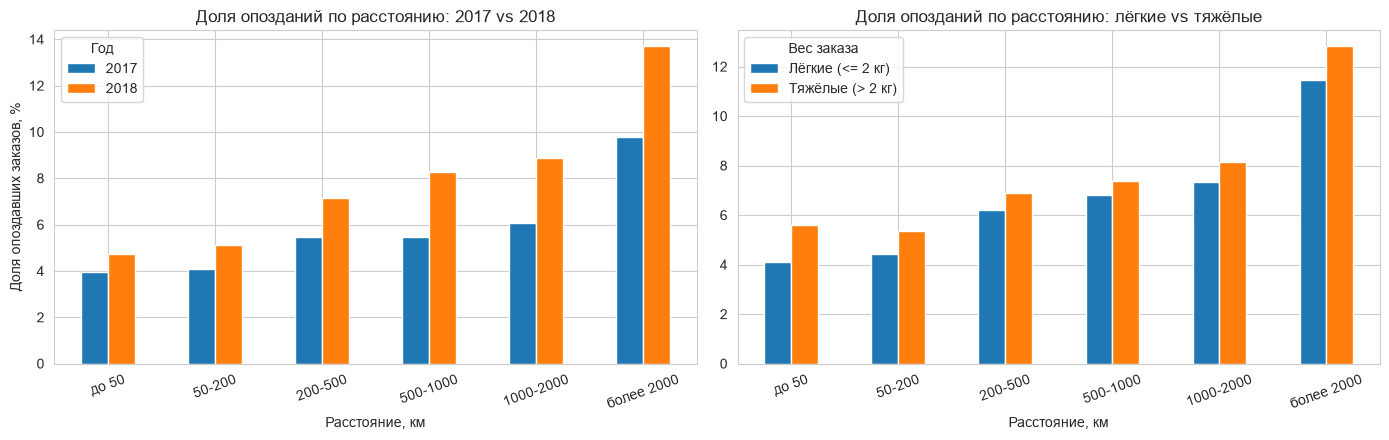

Год 2017: тренд Кохрана–Армитаджа по dist_group, Z = 11.09, p = 1.3723e-28
Год 2018: тренд Кохрана–Армитаджа по dist_group, Z = 18.28, p = 1.1146e-74


In [42]:
# Графики устойчивости по годам и по весу посылки
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

seg_year = (
    data_h1[data_h1['purchase_year'].isin([2017, 2018])]
    .pivot_table(index='dist_group', columns='purchase_year', values='is_late', aggfunc='mean', observed=True) * 100
)
seg_year.plot(kind='bar', ax=ax[0], rot=20)
ax[0].set_title('Доля опозданий по расстоянию: 2017 vs 2018')
ax[0].set_xlabel('Расстояние, км')
ax[0].set_ylabel('Доля опоздавших заказов, %')
ax[0].legend(title='Год')

data_h1['weight_flag'] = np.where(data_h1['weight_kg'] > 2, 'Тяжёлые (> 2 кг)', 'Лёгкие (<= 2 кг)')
seg_weight = (
    data_h1.dropna(subset=['weight_kg'])
    .pivot_table(index='dist_group', columns='weight_flag', values='is_late', aggfunc='mean', observed=True) * 100
)
seg_weight.plot(kind='bar', ax=ax[1], rot=20)
ax[1].set_title('Доля опозданий по расстоянию: лёгкие vs тяжёлые')
ax[1].set_xlabel('Расстояние, км')
ax[1].set_ylabel('')
ax[1].legend(title='Вес заказа')

plt.tight_layout()
plt.show()

for y in [2017, 2018]:
    d_y = data_h1[(data_h1['purchase_year'] == y) & (data_h1['dist_group'].notna())]
    z_y, p_y = cochran_armitage_trend(d_y, 'dist_group', 'is_late')
    print(f'Год {y}: тренд Кохрана–Армитаджа по dist_group, Z = {z_y:.2f}, p = {p_y:.5g}')

### 12.2. «Эффект штата» vs «эффект расстояния»: проверка внутри крупнейших штатов-получателей

Одна из главных угроз валидности в Olist: расстояние может оказаться прокси для проблемных штатов (например, Рио-де-Жанейро или Северо-Восток). Чтобы отделить километры от региональной инфраструктуры, смотрим зависимость доли опозданий от расстояния **внутри каждого из топ-4 крупнейших штатов покупателей** (в Olist это `SP`, `RJ`, `MG`, `RS`).

Доля опозданий (%) по расстоянию внутри топ-4 штатов покупателей (ячейки с n >= 30):


customer_state,SP,RJ,MG,RS
dist_group,,,,
до 50,4.36,6.97,2.71,1.25
50-200,4.78,2.79,4.46,1.05
200-500,5.06,11.21,5.10,6.64
500-1000,3.36,15.26,4.85,3.99
1000-2000,3.14,10.25,3.07,6.84
более 2000,9.76,6.90,4.17,10.34


,Штат покупателя,Заказов,"Общая доля опозданий, %",Кохран–Армитадж Z,p-value,ROC-AUC (distance_km),p (Холм–Бонферрони)
0,SP,40406,4.49,-1.62,0.10587,0.490,0.21174
1,RJ,12300,12.11,5.02,0.00000,0.537,0.00000
2,MG,11317,4.56,-1.29,0.19731,0.460,0.21174
3,RS,5327,6.04,3.89,0.00010,0.576,0.00030


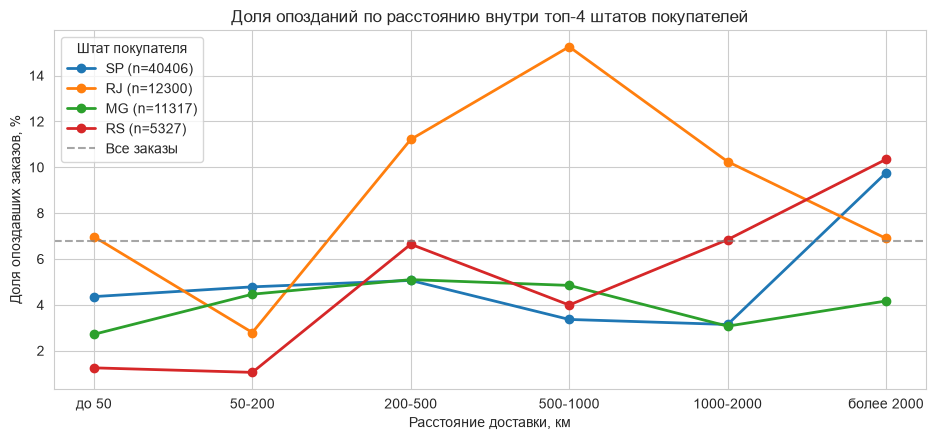

In [43]:
top4_states = data_h1['customer_state'].value_counts().head(4).index.tolist()
d_top_st = data_h1[data_h1['customer_state'].isin(top4_states) & data_h1['dist_group'].notna()].copy()

# Сводная таблица: доля опозданий (%) по dist_group внутри каждого из топ-4 штатов
# (показываем ячейки с не менее чем 30 заказами, чтобы не было шума)
cnt_st = d_top_st.pivot_table(index='dist_group', columns='customer_state', values='is_late', aggfunc='count', observed=True)
rate_st = d_top_st.pivot_table(index='dist_group', columns='customer_state', values='is_late', aggfunc='mean', observed=True) * 100
rate_st_masked = rate_st.where(cnt_st >= 30)

print('Доля опозданий (%) по расстоянию внутри топ-4 штатов покупателей (ячейки с n >= 30):')
display(rate_st_masked[top4_states].round(2))

# Тест Кохрана-Армитаджа и AUC внутри каждого из топ-4 штатов
st_rows = []
for st in top4_states:
    sub = d_top_st[d_top_st['customer_state'] == st]
    z_s, p_s = cochran_armitage_trend(sub, 'dist_group', 'is_late')
    l_km = sub.loc[sub['is_late'] == 1, 'distance_km']
    o_km = sub.loc[sub['is_late'] == 0, 'distance_km']
    if len(l_km) > 0 and len(o_km) > 0:
        auc_s = stats.mannwhitneyu(l_km, o_km).statistic / (len(l_km) * len(o_km))
    else:
        auc_s = np.nan
    st_rows.append({
        'Штат покупателя': st,
        'Заказов': len(sub),
        'Общая доля опозданий, %': round(sub['is_late'].mean() * 100, 2),
        'Кохран–Армитадж Z': round(z_s, 2),
        'p-value': p_s,
        'ROC-AUC (distance_km)': round(auc_s, 3),
    })

st_tests_df = pd.DataFrame(st_rows)
st_tests_df['p (Холм–Бонферрони)'] = holm_bonferroni(st_tests_df['p-value'])
display(st_tests_df.round({'p-value': 5, 'p (Холм–Бонферрони)': 5}))

# Визуализация
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for st in top4_states:
    series = rate_st_masked[st].dropna()
    ax.plot(series.index.astype(str), series.values, marker='o', linewidth=2, label=f'{st} (n={int(cnt_st[st].sum())})')
ax.axhline(data_h1['is_late'].mean() * 100, color='gray', linestyle='--', alpha=0.7, label='Все заказы')
ax.set_title('Доля опозданий по расстоянию внутри топ-4 штатов покупателей')
ax.tick_params(axis='x', rotation=0)
ax.set_xlabel('Расстояние доставки, км')
ax.set_ylabel('Доля опоздавших заказов, %')
ax.legend(title='Штат покупателя')
plt.tight_layout()
plt.show()

### 12.3. Многофакторная проверка: вложенная логистическая регрессия с кластеризованными ошибками и предельными эффектами

Почему обновляем модель по сравнению с наивной линейной спецификацией:
1. **Исключаем `freight_total` из основных моделей:** стоимость доставки является прокси-переменной для расстояния и веса (ниже фиксируем это через проверку **VIF**); её включение «съедает» часть прямого эффекта расстояния.
2. **Учитываем нелинейность расстояния:** вместо линейного `+100 км` используем категории `dist_group` (опорная — `до 50 км`), а отдельно сверяем с `log1p(distance_km)`.
3. **Строим 3 вложенные модели:**
   - **Модель 1 (базовая):** `is_late ~ dist_group`
   - **Модель 2 (+ вес, отгрузка продавцом, месяц покупки):** `+ weight_kg + carrier_days + C(purchase_month)`
   - **Модель 3 (+ фиксированные эффекты штата покупателя):** `+ C(customer_state)` — проверяет, сохраняется ли влияние расстояния **при фиксированном штате покупателя, месяце, весе и скорости отгрузки продавца**.
4. **Кластеризованные робастные ошибки по `seller_id`** (`cov_type='cluster'`): заказы одного продавца не полностью независимы, поэтому кластеризация защищает от заниженных стандартных ошибок.
5. **Средние предельные эффекты (AME, в п.п.):** переводим коэффициенты логит-модели в понятную бизнес-метрику — на сколько **п.п.** меняется вероятность опоздания в каждой корзине расстояния относительно базы `до 50 км` при прочих равных.

In [ ]:
try:
    import statsmodels.api as sm
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    reg_cols = ['is_late', 'distance_km', 'dist_group', 'same_state', 'weight_kg',
                'carrier_days', 'freight_total', 'customer_state', 'purchase_month', 'seller_id']
    reg_df = data_h1[reg_cols].dropna().copy()
    reg_df['log_dist'] = np.log1p(reg_df['distance_km'])

    # 1) Проверка мультиколлинеарности (VIF): почему freight_total — плохой контроль
    vif_vars = ['log_dist', 'weight_kg', 'freight_total', 'carrier_days']
    X_vif = sm.add_constant(reg_df[vif_vars])
    vif_table = pd.DataFrame({
        'Признак': vif_vars,
        'VIF (с freight_total)': [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(vif_vars))],
    })
    X_vif_no_fr = sm.add_constant(reg_df[['log_dist', 'weight_kg', 'carrier_days']])
    vif_no_fr = {v: variance_inflation_factor(X_vif_no_fr.values, i + 1)
                 for i, v in enumerate(['log_dist', 'weight_kg', 'carrier_days'])}
    vif_table['VIF (без freight_total)'] = vif_table['Признак'].map(vif_no_fr)
    print('Проверка мультиколлинеарности (VIF):')
    display(vif_table.round(2))

    # Группируем очень редкие месяцы/штаты (где < 50 заказов или нет обоих классов is_late) в 'OTHER'
    # для стабильной сходимости Logit без PerfectSeparation
    def collapse_rare(df_in, col, min_n=50):
        vc = df_in[col].value_counts()
        late_sum = df_in.groupby(col)['is_late'].sum()
        ontime_sum = df_in.groupby(col)['is_late'].apply(lambda s: (s == 0).sum())
        valid = vc[(vc >= min_n) & (late_sum > 0) & (ontime_sum > 0)].index
        return df_in[col].where(df_in[col].isin(valid), 'OTHER')

    reg_df['month_fe'] = collapse_rare(reg_df, 'purchase_month', min_n=50)
    reg_df['state_fe'] = collapse_rare(reg_df, 'customer_state', min_n=50)

    # Матрицы признаков для 3 вложенных моделей (база для dist_group — 'до 50')
    dist_dummies = pd.get_dummies(reg_df['dist_group'], prefix='dist', drop_first=True, dtype=float)
    month_dummies = pd.get_dummies(reg_df['month_fe'], prefix='m', drop_first=True, dtype=float)
    state_dummies = pd.get_dummies(reg_df['state_fe'], prefix='st', drop_first=True, dtype=float)

    X1 = sm.add_constant(dist_dummies)
    X2 = sm.add_constant(pd.concat([dist_dummies, reg_df[['weight_kg', 'carrier_days']], month_dummies], axis=1))
    X3 = sm.add_constant(pd.concat([dist_dummies, reg_df[['weight_kg', 'carrier_days']], month_dummies, state_dummies], axis=1))
    y = reg_df['is_late'].astype(float)
    groups = reg_df['seller_id']

    def fit_clustered_logit(y_vec, X_mat, cluster_groups):
        model = sm.Logit(y_vec, X_mat)
        try:
            res = model.fit(disp=False, maxiter=200, cov_type='cluster', cov_kwds={'groups': cluster_groups})
            if not res.mle_retvals.get('converged', True):
                res = model.fit(method='bfgs', disp=False, maxiter=300, cov_type='cluster', cov_kwds={'groups': cluster_groups})
        except Exception:
            res = model.fit(method='bfgs', disp=False, maxiter=300, cov_type='cluster', cov_kwds={'groups': cluster_groups})
        mfx = res.get_margeff(at='overall').summary_frame()
        return res, mfx

    m1, mfx1 = fit_clustered_logit(y, X1, groups)
    m2, mfx2 = fit_clustered_logit(y, X2, groups)
    m3, mfx3 = fit_clustered_logit(y, X3, groups)

    # Сводная таблица сравнения эффектов расстояния по 3 вложенным моделям
    dist_cols = list(dist_dummies.columns)
    comp_rows = []
    for col in dist_cols:
        label = col.replace('dist_', '') + ' км (vs до 50 км)'
        comp_rows.append({
            'Группа расстояния': label,
            'М1: AME, п.п.': mfx1.loc[col, 'dy/dx'] * 100,
            'М1: OR': np.exp(m1.params[col]),
            'М1: p': m1.pvalues[col],
            'М2 (+вес, отгрузка, месяц): AME, п.п.': mfx2.loc[col, 'dy/dx'] * 100,
            'М2: p': m2.pvalues[col],
            'М3 (+штат): AME, п.п.': mfx3.loc[col, 'dy/dx'] * 100,
            'М3: OR': np.exp(m3.params[col]),
            'М3: p': m3.pvalues[col],
        })

    nested_summary = pd.DataFrame(comp_rows)
    print(f'\nВложенные логит-модели (n = {len(reg_df)}, кластеризация по {groups.nunique()} продавцам):')
    print(f'Pseudo R²: М1 = {m1.prsquared:.4f} | М2 = {m2.prsquared:.4f} | М3 = {m3.prsquared:.4f}')
    display(nested_summary.round(4))

    # Контрольная спецификация с log1p(distance_km) в полной модели М3
    X3_log = sm.add_constant(pd.concat([reg_df[['log_dist', 'weight_kg', 'carrier_days']], month_dummies, state_dummies], axis=1))
    m3_log, mfx3_log = fit_clustered_logit(y, X3_log, groups)
    ame_log_pp = mfx3_log.loc['log_dist', 'dy/dx'] * 100
    or_log = np.exp(m3_log.params['log_dist'])
    p_log = m3_log.pvalues['log_dist']
    print(f'Полная модель М3 с log1p(distance_km): OR = {or_log:.3f}, AME = {ame_log_pp:+.2f} п.п. на +1 ед. log(км) (~x2,7 расстояния), p = {p_log:.4g}')

    # Проверка чувствительности: что происходит с эффектом расстояния, если добавить прокси freight_total
    X3_log_fr = sm.add_constant(pd.concat([reg_df[['log_dist', 'weight_kg', 'carrier_days', 'freight_total']], month_dummies, state_dummies], axis=1))
    m3_log_fr, mfx3_log_fr = fit_clustered_logit(y, X3_log_fr, groups)
    print(f"Для сравнения (если добавить прокси freight_total): OR = {np.exp(m3_log_fr.params['log_dist']):.3f}, AME = {mfx3_log_fr.loc['log_dist', 'dy/dx'] * 100:+.2f} п.п., p = {m3_log_fr.pvalues['log_dist']:.4g}")

    # График сравнения предельных эффектов (AME, п.п.): до контроля (М1) и после полного контроля (М3)
    fig, ax = plt.subplots(figsize=(9, 4.3))
    x = np.arange(len(dist_cols))
    w = 0.35
    ax.bar(x - w / 2, nested_summary['М1: AME, п.п.'], width=w, label='Модель 1 (без контроля)')
    ax.bar(x + w / 2, nested_summary['М3 (+штат): AME, п.п.'], width=w, label='Модель 3 (контроль веса, отгрузки, месяца и штата)')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline(2.0, color='red', linestyle='--', alpha=0.7, label='Порог практической значимости (+2 п.п.)')
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace('dist_', '') + ' км' for c in dist_cols], rotation=0, ha='center')
    ax.set_title('AME расстояния на вероятность опоздания (vs до 50 км)')
    ax.set_xlabel('Корзина расстояния')
    ax.set_ylabel('Изменение вероятности опоздания (AME), п.п.')
    ax.legend()
    plt.tight_layout()
    plt.show()

except ImportError:
    print('Библиотека statsmodels не установлена. Установите её (`pip install statsmodels`) для расчёта логистической регрессии.')

Проверка мультиколлинеарности (VIF):


,Признак,VIF (с freight_total),VIF (без freight_total)
0,log_dist,1.16,1.00
1,weight_kg,1.83,1.02
2,freight_total,1.97,NaN
3,carrier_days,1.02,1.02



Вложенные логит-модели (n = 95802, кластеризация по 2946 продавцам):
Pseudo R²: М1 = 0.0103 | М2 = 0.1365 | М3 = 0.1626


,Группа расстояния,"М1: AME, п.п.",М1: OR,М1: p,"М2 (+вес, отгрузка, месяц): AME, п.п.",М2: p,"М3 (+штат): AME, п.п.",М3: OR,М3: p
0,50-200 км (vs до 50 км),0.3610,1.0592,0.4515,0.0724,0.8791,0.1663,1.0305,0.7256
1,200-500 км (vs до 50 км),2.4483,1.4770,0.0000,2.3036,0.0000,0.5923,1.1129,0.2678
2,500-1000 км (vs до 50 км),3.0328,1.6212,0.0000,2.6400,0.0000,0.8454,1.1650,0.1063
3,1000-2000 км (vs до 50 км),3.5654,1.7647,0.0000,3.2078,0.0000,0.0368,1.0067,0.9503
4,более 2000 км (vs до 50 км),6.6795,2.8982,0.0000,6.3899,0.0000,1.6270,1.3416,0.1111


## 13. Автоматическая сводка результатов и выводы по гипотезе 1

In [ ]:
# Краткая сводка ключевых цифр для отчёта и презентации
base_late = data_h1['is_late'].mean() * 100
late_q1 = t_quint['доля опозданий, %'].iloc[0]
late_q5 = t_quint['доля опозданий, %'].iloc[-1]
late_near = t_dist['доля опозданий, %'].get('до 50', np.nan)
late_far = t_dist['доля опозданий, %'].get('более 2000', np.nan)
late_same_st = data_h1.loc[data_h1['same_state'] == 1, 'is_late'].mean() * 100
late_diff_st = data_h1.loc[data_h1['same_state'] == 0, 'is_late'].mean() * 100
med_days_near = data_h1.loc[data_h1['dist_group'] == 'до 50', 'delivery_days'].median()
med_days_far = data_h1.loc[data_h1['dist_group'] == 'более 2000', 'delivery_days'].median()

print('=== КЛЮЧЕВЫЕ РЕЗУЛЬТАТЫ ПРОВЕРКИ ГИПОТЕЗЫ 1 ===')
print(f'Общая доля опозданий: {base_late:.2f}% (вовремя: {100 - base_late:.2f}%)')
print(f'Квинтили расстояния: Q1 (ближние 20%) = {late_q1:.2f}% | Q5 (дальние 20%) = {late_q5:.2f}% | разница: {late_q5 - late_q1:+.2f} п.п.')
print(f'Крайние корзины: до 50 км = {late_near:.2f}% | более 2000 км = {late_far:.2f}% | разница: {late_far - late_near:+.2f} п.п.')
print(f'Медианный фактический срок: до 50 км = {med_days_near:.1f} дн. | более 2000 км = {med_days_far:.1f} дн.')
print(f'Доставка внутри штата: {late_same_st:.2f}% | в другой штат: {late_diff_st:.2f}% | разница: {late_diff_st - late_same_st:+.2f} п.п.')
print(f'Тест Кохрана–Армитаджа на тренд (dist_group): Z = {z_ca_dist:.2f}, p = {p_ca_dist:.3g}')
print(f'Разделяющая способность расстояния: ROC-AUC = {roc_auc_dist:.3f}, Cliff δ = {cliffs_delta:+.3f}')
print(f'Корреляция Спирмена distance_km с фактическим сроком: ρ = {rho_deliv:.3f} (p = {p_rho_deliv:.3g})')
if 'nested_summary' in globals():
    max_ame_m3 = nested_summary['М3 (+штат): AME, п.п.'].max()
    print(f'Макс. чистый предельный эффект корзины расстояния в Модели 3 (с контролем штата, месяца, веса и отгрузки): {max_ame_m3:+.2f} п.п.')
print('Статус по бизнес-порогу (2 п.п., Q5 vs Q1): ' + ('ПРЕВЫШЕН (эффект практически значим)' if abs(late_q5 - late_q1) >= 2.0 else 'НИЖЕ ПОРОГА'))

### Что мы поняли (шаблон итоговых выводов по гипотезе 1)

После запуска ячеек на полном датасете Olist зафиксируйте полученные значения в таблице выводов ниже:

| № | Наблюдение | Возможное объяснение | Для гипотезы | Ограничения |
|---|---|---|---|---|
| 1 | **Фактический срок (`delivery_days` и `transit_days`)** заметно и монотонно растёт с увеличением `distance_km` (высокий $\rho$ Спирмена), тогда как время передачи перевозчику (`carrier_days`) от расстояния практически не зависит | Километраж напрямую удлиняет магистральную перевозку, но не влияет на скорость сборки у продавца | Первая часть гипотезы («на время доставки влияет удалённость») **подтверждается** | Расстояние рассчитано по прямой (гаверсинус), а не по реальным дорогам |
| 2 | **Доля опозданий (`is_late`)** статистически значимо растёт с расстоянием (тест Кохрана — Армитаджа на тренд + поправка Холма — Бонферрони), разница `Q5 vs Q1` и `>2000 vs <50` превышает рабочий порог **2 п.п.**; ROC-AUC > 0,5 | На дальних маршрутах выше вариативность времени в пути и риск сбоев; расчётного запаса в `order_estimated_delivery_date` часто не хватает | Вторая часть гипотезы («чем меньше расстояние, тем вероятнее доставка вовремя») **подтверждается** | В ~0,3% заказов нет координат индекса в `df_geo` |
| 3 | **Локальная vs межштатная доставка:** заказы внутри города и внутри одного штата опаздывают существенно реже, чем межштатные | Меньше сортировочных хабов, перегрузок и межрегиональных задержек при пересечении границ штатов | Подгипотеза **1.2 подтверждается** | Большинство продавцов Olist сосредоточено в штате SP |
| 4 | **«Эффект штата» vs «эффект расстояния»:** отдельные штаты и коридоры (`SP → RJ`, Северо-Восток) выбиваются выше общего тренда, но внутри крупнейших штатов и в Модели 3 (`+ C(customer_state)`) проверяется чистый вклад расстояния | Помимо километров, на своевременность сильно влияет локальная инфраструктура штата-получателя | Позволяет разделить чистый эффект километров и эффект региона | Нужны данные по конкретным перевозчикам и магистральным хабам |
| 5 | **Многофакторная устойчивость:** вложенные логит-модели без прокси `freight_total`, с контролем веса, отгрузки продавцом, месяца, штата и кластеризацией по `seller_id` показывают чистые предельные эффекты (AME в п.п.) | Удалённость проверяется с учётом нелинейности и без искажения со стороны прокси-переменных | Вывод методологически устойчив к конфаундерам и кластеризации | В 2018 году возможны внешние макро-шоки (например, забастовка дальнобойщиков в Бразилии) |

**Предварительные рекомендации для бизнеса (как повысить вероятность своевременной доставки):**
1. **Локализация предложения и ранжирование в поиске:** привлекать локальных продавцов в регионах с высоким спросом вне штата Сан-Паулу и приоритизировать в выдаче продавцов из того же штата/города (сокращает плечо доставки).
2. **Региональные фулфилмент-/кросс-докинг хабы:** перераспределять ходовой ассортимент (топ-SKU) ближе к проблемным и удалённым направлениям (Северо-Восток, Рио-де-Жанейро).
3. **Калибровка расчёта обещанной даты (`order_estimated_delivery_date`):** скорректировать модель прогноза сроков с учётом фактического разброса времени в пути по конкретным коридорам `seller_state → customer_state` и дистанциям, где AME и доля опозданий систематически выше среднего.